# Liquid thermal boundary layer under rocHPL power traces

This notebook applies the **1D unperturbed liquid boundary-layer model** from
`reference/liquid boundary layer under square wave heating.pdf` to GPU power measured with Score-P and loaded through **Ampere**.

1. **Replicate the model results** (`reference/liquid_BL_results.pdf`) for a single square wave: $q''_{peak}$ = 20 W/cm², $P$ = 50 ms, $t_{on}$ = 25 ms.
2. **Load a rocHPL trace with Ampere** (Frontier, 1 node, `P=1 Q=8 N=245760`) and turn the GCD energy counter into a wall heat flux over the **full trace**.
3. **Use the FFT to break the full trace into a sum of square waves**, window by window, so the ms-scale spikes are kept.
4. **Apply the model to each square wave and superpose the results** to predict the cooling response (liquid superheat $\Theta(y,t)$) over the full run.
5. **Catalogue the square waves** (period, amplitude, periodic wall swing, penetration depth).

The model (eq. 32 of the derivation), for a square wave that starts at $t=0$:

$$
\Theta(y,t) = \frac{2 q''_{peak}\sqrt{\alpha_l}}{k_l}\sum_{n=0}^{N(t)}\left[\sqrt{\Delta t_{n,on}}\;\mathrm{ierfc}\!\left(\frac{y}{2\sqrt{\alpha_l \Delta t_{n,on}}}\right) - \sqrt{\Delta t_{n,off}}\;\mathrm{ierfc}\!\left(\frac{y}{2\sqrt{\alpha_l \Delta t_{n,off}}}\right) H(\Delta t_{n,off})\right]
$$

The PDE is linear, so the response to *any* sum of square waves (plus a DC level) is the sum of the responses to each one.

### Units cheat sheet

| Unit | What it is | Everyday reading |
|---|---|---|
| **K** (kelvin) | temperature | A *change* of 1 K equals a change of 1 °C. All temperatures here are differences ("degrees above the liquid's boiling point"), so read K as °C. Plots label them °C. |
| **superheat**, $\Theta$ | how far the liquid is above its boiling point, in °C | 0 °C = exactly at boiling. Bubbles start forming some tens of °C above. |
| **W** (watt) | power = energy per second (1 W = 1 J/s) | The GPU draws about 90 W idle and 500–700 W in HPL. |
| **W/cm²** (heat flux, $q''$) | power spread over the chip's area | With the assumed 14.5 cm² heater, multiply by 14.5 to get GPU watts: 40 W/cm² ≈ 580 W. |
| **J** (joule) | energy | Temperature depends on *how fast* energy arrives (W), not just how much (J). The same joules in 1 ms or in 1 s give very different temperatures. |
| **ms**, **µm** | milliseconds; micrometres (millionths of a metre) | A human hair is about 70 µm thick. |
| **Hz** | events per second | A 12 ms rhythm is about 82 Hz. |

Physics notation used in some plots: $y$ = distance from the chip surface into the liquid; *wall* = the chip surface itself; $\alpha$, $e$, $k$ = fixed properties of the liquid (how fast heat spreads in it, how easily it soaks up heat, how well it conducts).

In [31]:
import re, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import erfc
from scipy.signal import fftconvolve
from scipy.ndimage import uniform_filter1d

from ampere import Ensemble, MetricConfig, MetricType, set_backend
set_backend('pandas')          # no Arkouda server needed for a single-node trace

ROOT = Path('.').resolve()
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## Parameters

The derivation PDF doesn't list fluid properties. They were recovered from `liquid_BL_results.pdf` (see the appendix):

* The wall curve depends only on the **effusivity** $e=\sqrt{k\rho c_p}=k/\sqrt{\alpha}$. A least-squares fit to the blue curve gives $e$ = 369.46 W s$^{1/2}$ m$^{-2}$ K$^{-1}$ with an RMS residual of 0.025 K.
* The heatmap fixes the **diffusivity**: $\alpha$ = 3.871×10⁻⁸ m²/s. This matches HFE-7100 ($\alpha \approx 3.86\times10^{-8}$). The horizontal white line in the PDF heatmap sits at $4\sqrt{\alpha\, t_{end}}$ = 393 µm.

So $k_l$ = 0.0727 W/m·K and $\rho_l c_{p,l}$ = 1.878×10⁶ J/m³·K. Replace these with your coolant's values if they differ.

The **heater area** converts GPU power (W) to wall heat flux (W/cm²). It is an assumption, so set it to your heater or cold-plate footprint.

In [32]:
# --- Liquid properties (recovered from liquid_BL_results.pdf; HFE-7100-like) ---
ALPHA = 3.8708e-8                 # m^2/s   thermal diffusivity
E_EFF = 369.458                   # W s^0.5 / (m^2 K)  effusivity sqrt(k rho cp)
K_L   = E_EFF * np.sqrt(ALPHA)    # W/(m K)
RHO_CP = E_EFF / np.sqrt(ALPHA)   # J/(m^3 K)

# --- Heater: GPU power -> wall heat flux ---
A_HEATER_CM2 = 14.5               # ASSUMPTION: MI250X OAM, ~2 GCD dies (~7.2 cm^2 each). Replace as needed.

# --- Trace ---
TRACE = ROOT / 'data' / 'rochpl-frontier'      # Ampere CSV export (rank 0 + node metrics), symlinked from ampere/examples/hpl-trace
DEVICE = 0                                      # GCD whose energy counter is used
GRID_DT = 1e-3                                  # 1 ms piecewise-constant grid for FFT / square waves
WINDOW_S = 0.125                                # short-time window for the square-wave decomposition
K_WINDOW = 12                                   # square waves fitted per window

print(f"k_l = {K_L:.4f} W/m/K, rho*cp = {RHO_CP:.4e} J/m^3/K, alpha = {ALPHA:.4e} m^2/s")

k_l = 0.0727 W/m/K, rho*cp = 1.8779e+06 J/m^3/K, alpha = 3.8708e-08 m^2/s


## Model implementation

* `theta_square_wave` is eq. 32 exactly as written: square wave on at $t=0$, period $P$, on-time $t_{on}$.
* `theta_steps` is the same superposition argument (eqs. 25–29) for an arbitrary list of flux steps $\Delta q_j$ at times $t_j$. Any piecewise-constant flux, including a measured trace or a phase-shifted square wave, is such a list.
* At the wall, $\mathrm{ierfc}(0)=1/\sqrt{\pi}$, so $\Theta_w(t) = \frac{2}{e\sqrt{\pi}}\sum_j \Delta q_j\sqrt{t-t_j}$.
* `theta_grid` evaluates the same sum for a flux on a uniform grid. There it is a discrete convolution of the steps $\Delta q_i$ with the eq. 26 kernel, done by FFT, so it scales to the full trace (≈80 000 steps).

In [33]:
def ierfc(z):
    '''Integrated complementary error function, ierfc(z) = exp(-z^2)/sqrt(pi) - z*erfc(z).

    erfc(z) is the standard "tail of a bell curve" function. It shows up whenever heat diffuses from a
    surface: the temperature at depth y after time t depends on y only through z = y / (2*sqrt(alpha*t)).
    ierfc is its integral and gives the temperature *shape* under a constant heat flux: 1/sqrt(pi) at the
    wall (z = 0), falling smoothly to 0 deep in the liquid (z of about 2 or more, i.e. y > 4*sqrt(alpha*t)).
    '''
    return np.exp(-z * z) / np.sqrt(np.pi) - z * erfc(z)

def theta_kernel(y, dt, alpha=ALPHA, e=E_EFF):
    '''Step response (eq. 26): superheat [K] per 1 W/m^2 of heat flux switched on `dt` seconds ago.

    This is the model's basic building block. Switch on a constant heat flux q at the wall of a
    still liquid. After time dt the liquid at distance y from the wall is warmer than saturation by
        Theta = q * (2/e) * sqrt(dt) * ierfc(y / (2*sqrt(alpha*dt)))
    with `e` the liquid's effusivity (how easily it soaks up heat) and `alpha` its thermal diffusivity
    (how fast heat spreads). At the wall this grows like sqrt(dt): heating keeps warming the wall,
    more and more slowly. The heated layer is about 4*sqrt(alpha*dt) thick. Returns 0 for dt <= 0 (not switched on yet).

    y, dt: distance from wall [m], time since the step [s] (arrays broadcast together).
    '''
    dt = np.asarray(dt, float)
    ok = dt > 0
    tau = np.where(ok, dt, 1.0)
    return np.where(ok, 2.0 / e * np.sqrt(tau) * ierfc(y / (2 * np.sqrt(alpha * tau))), 0.0)

def theta_square_wave(y, t, q_peak, P, t_on, alpha=ALPHA, e=E_EFF):
    '''Eq. 32: superheat [K] at (y, t) for a square-wave heat flux switched on at t = 0.

    The flux is q_peak [W/m^2] for t_on seconds, then 0 for P - t_on seconds, repeating every P seconds.
    The heat equation is linear, so responses add: a square wave is "step up by +q_peak at every n*P"
    plus "step down by -q_peak at every n*P + t_on", and the answer is the sum of `theta_kernel` for
    all of those steps. That sum is eq. 32.
    '''
    y, t = np.broadcast_arrays(np.asarray(y, float), np.asarray(t, float))
    out = np.zeros_like(t)
    for n in range(int(np.floor(t.max() / P)) + 1):
        out += theta_kernel(y, t - n * P, alpha, e) - theta_kernel(y, t - n * P - t_on, alpha, e)
    return q_peak * out

def theta_steps(y, t, t_j, dq_j, alpha=ALPHA, e=E_EFF, chunk=256):
    '''Superheat [K] at (y, t) for any heat flux made of steps: the general form of eq. 32.

    Any piecewise-constant flux is a list of jumps: at time t_j the flux changes by dq_j [W/m^2]
    (positive = up, negative = down). Because the model is linear, the total response is the sum of
    one step response per jump: Theta(y, t) = sum_j dq_j * theta_kernel(y, t - t_j).
    Direct sum over every (evaluation point, step) pair, computed `chunk` steps at a time to limit memory.
    '''
    y, t = np.broadcast_arrays(np.asarray(y, float), np.asarray(t, float))
    out = np.zeros(t.shape)
    for i in range(0, len(t_j), chunk):
        tj, dq = t_j[i:i + chunk], dq_j[i:i + chunk]
        out += (dq * theta_kernel(y[..., None], t[..., None] - tj, alpha, e)).sum(-1)
    return out

def steps_from_grid(q, dt, t0=0.0):
    '''Turn a sampled flux into the list of jumps that `theta_steps` needs.

    q[i] is the flux held constant on [t0 + i*dt, t0 + (i+1)*dt). The jump at the start of cell i is
    q[i] - q[i-1] (with q[-1] = 0, so the first jump switches the flux on). Cells with no change are dropped.
    Returns (step times [s], step sizes [W/m^2]).
    '''
    dq = np.diff(np.concatenate([[0.0], q]))
    tj = t0 + np.arange(len(q)) * dt
    m = dq != 0
    return tj[m], dq[m]

def theta_grid(q, dt, y, alpha=ALPHA, e=E_EFF):
    '''Same result as `theta_steps`, but fast enough for the full 82 s trace (~80 000 steps).

    On a uniform grid, the jump at cell i is dq[i] and the response at time n*dt is
        Theta[n] = sum_i dq[i] * theta_kernel(y, (n - i) * dt).
    That's a convolution (sliding weighted sum) of the jumps with the step response, which an FFT
    computes in O(N log N) instead of O(N^2). Done once per depth in `y`.
    Returns superheat [K] with shape (len(y), len(q)), at times t = n*dt.
    '''
    dq = np.diff(np.concatenate([[0.0], q]))
    lag = np.arange(len(q)) * dt
    return np.array([fftconvolve(dq, theta_kernel(yi, lag, alpha, e))[:len(q)] for yi in np.atleast_1d(y)])

### What each model function does, in pictures

1. **`ierfc`**: the shape of the warm layer. Its value at the wall is $1/\sqrt\pi$, and it is essentially 0 beyond $z\approx2$, i.e. beyond $y = 4\sqrt{\alpha t}$.
2. **`theta_kernel` at the wall**: switch on 20 W/cm² and hold it. The wall warms like $\sqrt t$: fast at first, then slower and slower, but it never levels off, because nothing removes the heat.
3. **`theta_kernel` vs depth**: the same step seen inside the liquid at several times. The warm layer gets thicker like $\sqrt t$ (dotted lines are $4\sqrt{\alpha t}$).
4. **`theta_square_wave`**: a square wave is a train of +q steps (red) and −q steps (blue). Each step makes its own $\sqrt t$ curve, and the black sum is eq. 32.
5. **`steps_from_grid`**: a sampled flux (made-up example) becomes its list of jumps $\Delta q_j$ (stems).
6. **`theta_steps` vs `theta_grid`**: one step-response curve per jump (thin), their sum (black), and the FFT-convolution shortcut (yellow dashes), which gives the same answer.

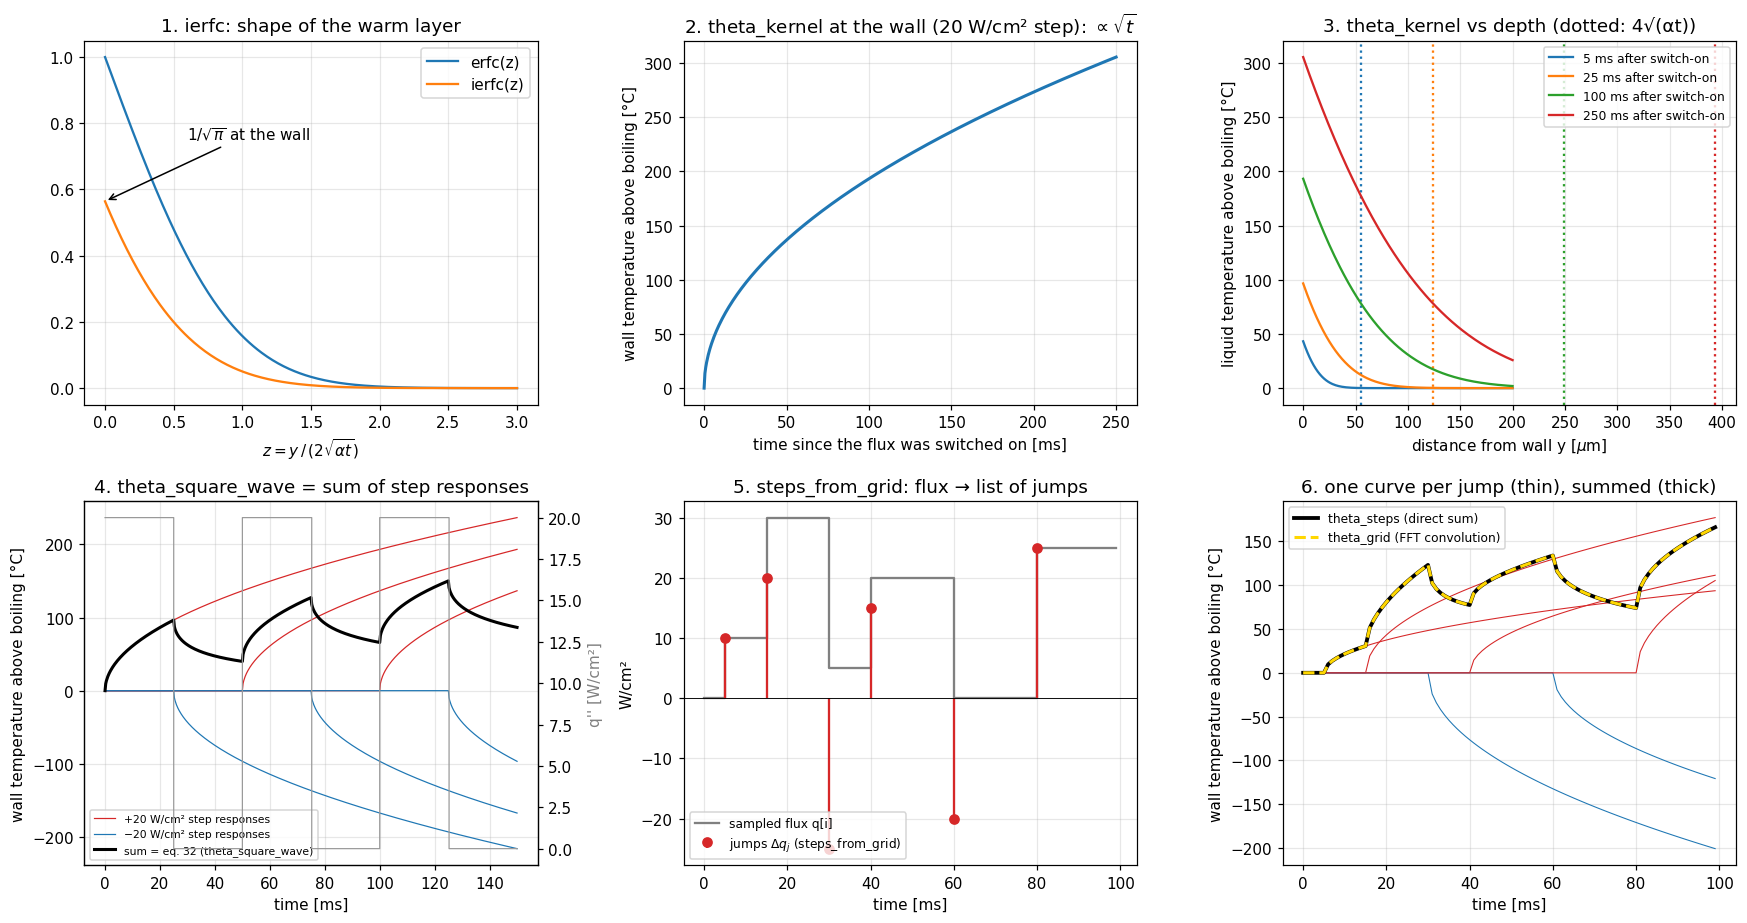

In [34]:
def demo_model_functions():
    q = 20e4                                                   # 20 W/cm^2
    fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
    z = np.linspace(0, 3, 301)
    a = ax[0, 0]; a.plot(z, erfc(z), label='erfc(z)'); a.plot(z, ierfc(z), label='ierfc(z)')
    a.annotate(r'$1/\sqrt{\pi}$ at the wall', (0, 1 / np.sqrt(np.pi)), xytext=(0.6, 0.75), arrowprops=dict(arrowstyle='->'))
    a.set(xlabel=r'$z = y\,/\,(2\sqrt{\alpha t})$', title='1. ierfc: shape of the warm layer'); a.legend()

    dts = np.linspace(0, 0.25, 501)
    a = ax[0, 1]; a.plot(dts * 1e3, q * theta_kernel(0, dts), lw=2)
    a.set(xlabel='time since the flux was switched on [ms]', ylabel='wall temperature above boiling [°C]', title=r'2. theta_kernel at the wall (20 W/cm² step): $\propto\sqrt{t}$')

    yy = np.linspace(0, 200e-6, 201); a = ax[0, 2]
    for dt in [0.005, 0.025, 0.1, 0.25]:
        l, = a.plot(yy * 1e6, q * theta_kernel(yy, dt), label=f'{dt*1e3:.0f} ms after switch-on')
        a.axvline(4 * np.sqrt(ALPHA * dt) * 1e6, color=l.get_color(), ls=':')
    a.set(xlabel=r'distance from wall y [$\mu$m]', ylabel='liquid temperature above boiling [°C]', title='3. theta_kernel vs depth (dotted: 4√(αt))'); a.legend(fontsize=8)

    P, ton = 0.05, 0.025; tt = np.linspace(0, 0.15, 601); a = ax[1, 0]
    for n in range(3):
        a.plot(tt * 1e3, q * theta_kernel(0, tt - n * P), color='tab:red', lw=0.8, label='+20 W/cm² step responses' if n == 0 else None)
        a.plot(tt * 1e3, -q * theta_kernel(0, tt - n * P - ton), color='tab:blue', lw=0.8, label='−20 W/cm² step responses' if n == 0 else None)
    a.plot(tt * 1e3, theta_square_wave(0, tt, q, P, ton), 'k', lw=2, label='sum = eq. 32 (theta_square_wave)')
    b = a.twinx(); b.step(tt * 1e3, q * (np.mod(tt, P) < ton) / 1e4, color='0.6', where='post', lw=0.8); b.set_ylabel("q'' [W/cm²]", color='0.5'); b.grid(False)
    a.set(xlabel='time [ms]', ylabel='wall temperature above boiling [°C]', title='4. theta_square_wave = sum of step responses'); a.legend(fontsize=7, loc='lower left')

    cells = np.array([0, 10, 10, 30, 30, 30, 5, 5, 20, 20, 20, 20, 0, 0, 0, 0, 25, 25, 25, 25])   # W/cm^2, 5 ms each
    q_toy = np.repeat(cells, 5) * 1e4; t_toy = np.arange(len(q_toy)) * 1e-3
    tj, dqj = steps_from_grid(q_toy, 1e-3)
    a = ax[1, 1]; a.step(t_toy * 1e3, q_toy / 1e4, where='post', color='0.5', label="sampled flux q[i]")
    a.stem(tj * 1e3, dqj / 1e4, linefmt='C3-', markerfmt='C3o', basefmt=' ', label=r'jumps $\Delta q_j$ (steps_from_grid)')
    a.axhline(0, color='k', lw=0.6)
    a.set(xlabel='time [ms]', ylabel='W/cm²', title='5. steps_from_grid: flux → list of jumps'); a.legend(fontsize=8)

    a = ax[1, 2]
    for t_j, d in zip(tj, dqj):
        a.plot(t_toy * 1e3, d * theta_kernel(0, t_toy - t_j), color='tab:red' if d > 0 else 'tab:blue', lw=0.7)
    a.plot(t_toy * 1e3, theta_steps(0, t_toy, tj, dqj), 'k', lw=2.5, label='theta_steps (direct sum)')
    a.plot(t_toy * 1e3, theta_grid(q_toy, 1e-3, [0.0])[0], '--', color='gold', lw=2, label='theta_grid (FFT convolution)')
    a.set(xlabel='time [ms]', ylabel='wall temperature above boiling [°C]', title='6. one curve per jump (thin), summed (thick)'); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'howto_model_functions.png', bbox_inches='tight')

demo_model_functions()

## Part 1: Replicate `liquid_BL_results.pdf` (single square wave)

In [35]:
Q_PEAK = 20e4      # 20 W/cm^2 -> W/m^2
P_SQ, T_ON = 0.050, 0.025
T_END, Y_MAX = 0.250, 500e-6

t = np.linspace(0, T_END, 1001)
y = np.linspace(0, Y_MAX, 251)
Y, T = np.meshgrid(y, t, indexing='ij')
field = theta_square_wave(Y, T, Q_PEAK, P_SQ, T_ON)
theta_w = field[0]
q_sq = Q_PEAK * (np.mod(t, P_SQ) < T_ON)

# Check: general step superposition == eq. 32
tj = np.sort(np.concatenate([np.arange(0, T_END, P_SQ), np.arange(T_ON, T_END, P_SQ)]))
dq = np.where(np.isclose(np.mod(tj, P_SQ), 0), Q_PEAK, -Q_PEAK)
print("max |eq.32 - step superposition| =", np.abs(theta_steps(0, t, tj, dq) - theta_w).max(), "K")

# Compare to the curve extracted from the PDF
ref = pd.read_csv(ROOT / 'reference' / 'liquid_BL_results_wall_superheat.csv', comment='#')
th_ref_model = theta_square_wave(0, ref.t_ms.values / 1e3, Q_PEAK, P_SQ, T_ON)
print(f"vs. PDF curve: RMS error = {np.sqrt(np.mean((th_ref_model - ref.theta_w_K)**2)):.3f} K, "
      f"peaks: model {theta_w.max():.1f} K / PDF {ref.theta_w_K.max():.1f} K")

max |eq.32 - step superposition| = 4.831690603168681e-13 K
vs. PDF curve: RMS error = 0.025 K, peaks: model 185.6 K / PDF 185.5 K


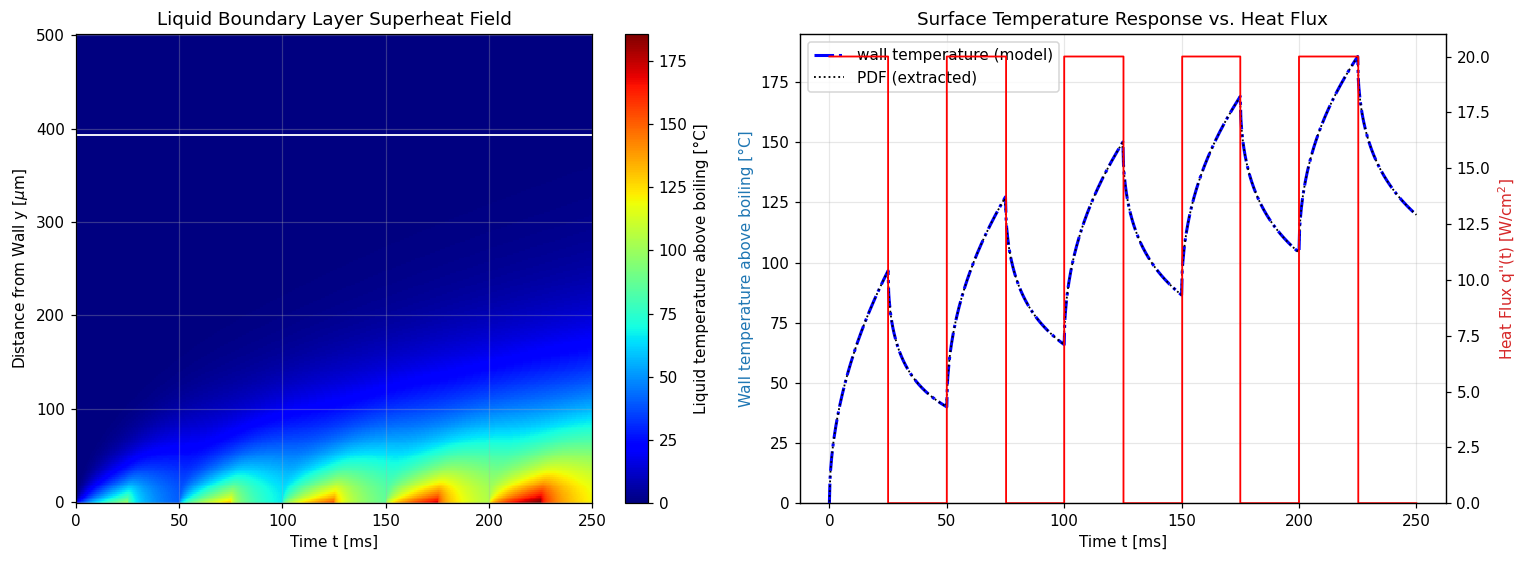

In [36]:
def plot_pdf_style(t, y, field, q_t, q_wall, title_suffix='', ref=None, q_label="Heat Flux q''(t) [W/cm$^2$]", fname=None):
    '''Two-panel figure laid out like `reference/liquid_BL_results.pdf`.

    Left: heatmap of the superheat field[y, t] (white line: thermal-layer thickness 4*sqrt(alpha*t_end)).
    Right: wall superheat field[0] (blue) against the heat flux q_wall(q_t) (red), plus an optional
    reference curve `ref` = (t_ms, theta).
    '''
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2))
    im = a1.pcolormesh(t * 1e3, y * 1e6, field, cmap='jet', shading='auto', vmin=0)
    a1.axhline(4 * np.sqrt(ALPHA * t[-1]) * 1e6, color='w', lw=1.2)
    a1.set(xlabel='Time t [ms]', ylabel=r'Distance from Wall y [$\mu$m]', title='Liquid Boundary Layer Superheat Field' + title_suffix)
    fig.colorbar(im, ax=a1, label='Liquid temperature above boiling [°C]')
    a2.plot(t * 1e3, field[0], 'b-.', lw=2, label='wall temperature (model)')
    if ref is not None:
        a2.plot(ref[0], ref[1], 'k:', lw=1.2, label='PDF (extracted)')
    a2.set(xlabel='Time t [ms]', ylabel='Wall temperature above boiling [°C]', title='Surface Temperature Response vs. Heat Flux' + title_suffix)
    a2.yaxis.label.set_color('tab:blue'); a2.set_ylim(bottom=0)
    b = a2.twinx(); b.step(q_t * 1e3, q_wall / 1e4, 'r', where='post', lw=1.2)
    b.set_ylabel(q_label, color='tab:red'); b.set_ylim(bottom=0); b.grid(False)
    a2.legend(loc='upper left')
    fig.tight_layout()
    if fname: fig.savefig(FIG / fname, bbox_inches='tight')
    return fig

plot_pdf_style(t, y, field, t, q_sq, ref=(ref.t_ms, ref.theta_w_K), fname='part1_replicated_square_wave.png');

The replicated wall superheat matches the PDF curve to within a few hundredths of a kelvin RMS. The heatmap shows the same growing thermal layer (≈100 µm at 250 ms), and the white line marks $4\sqrt{\alpha t_{end}}$.

## Part 2: Load the rocHPL trace with Ampere

Ampere's `CUMULATIVE` metric type turns the `rocm_smi` energy counter into joules. The power over each native counter interval is $\Delta E/\Delta t$. This trace predates the February driver change, so the counter updates about every 3.3 ms.

In [37]:
configs = {
    re.compile(r".*rocm_smi.*energy.*"): MetricConfig(MetricType.CUMULATIVE, scale_factor=1e-6),       # uJ -> J
    re.compile(r".*rocm_smi.*power.*"):  MetricConfig(MetricType.INSTANTANEOUS, scale_factor=1e-6),    # uW -> W
}
ensemble = Ensemble.from_trace_paths([str(TRACE)], {"Node0": ["MPI Rank 0"]}, configs)
node = ensemble.runs[0].nodes[0]
rank0 = node.ranks[0]

energy = node.metrics[f"A2rocm_smi:::energy_count:device={DEVICE}"]
t_E = np.asarray(energy.times.to_ndarray()); E_J = np.asarray(energy.values.to_ndarray())
p_native = np.diff(E_J) / np.diff(t_E)                     # W on [t_E[i], t_E[i+1])
print(f"{len(t_E)} energy samples over {t_E[-1]-t_E[0]:.1f} s; median update interval {np.median(np.diff(t_E))*1e3:.2f} ms")

# Locate the HPL factorization with Ampere's call graph
names = np.asarray(rank0.names.to_ndarray()); starts = np.asarray(rank0.starts.to_ndarray()); ends = np.asarray(rank0.ends.to_ndarray())
i_ges = np.flatnonzero(np.char.startswith(names.astype(str), 'HPL_pdgesv'))[0]
T_GESV0, T_GESV1 = starts[i_ges], ends[i_ges]
print(f"HPL_pdgesv: {T_GESV0:.3f} s -> {T_GESV1:.3f} s ({T_GESV1-T_GESV0:.1f} s)")

# Sanity check: 1 s binned energy-derived power vs. the firmware's power_average sensor
edges = np.arange(t_E[0], t_E[-1], 1.0)
p_1s = np.asarray(energy.get_delta_vectorized(edges[:-1], edges[1:]))
pav = node.metrics[f"A2rocm_smi:::power_average:device={DEVICE}:sensor=0"]
pav_1s = np.interp(edges[:-1] + 0.5, np.asarray(pav.times.to_ndarray()), np.asarray(pav.values.to_ndarray()))
print(f"mean |dE/dt - power_average| over 1 s bins: {np.mean(np.abs(p_1s - pav_1s)):.1f} W (mean power {p_1s.mean():.0f} W)")

Loading Runs: 100%|██████████| 1/1 [00:01<00:00,  1.17s/it]


21216 energy samples over 82.2 s; median update interval 3.32 ms
HPL_pdgesv: 18.915 s -> 81.591 s (62.7 s)
mean |dE/dt - power_average| over 1 s bins: 16.5 W (mean power 447 W)


full trace: 82.2 s on a 1 ms grid (82232 cells); mean flux 30.8 W/cm^2, peak 67.6 W/cm^2


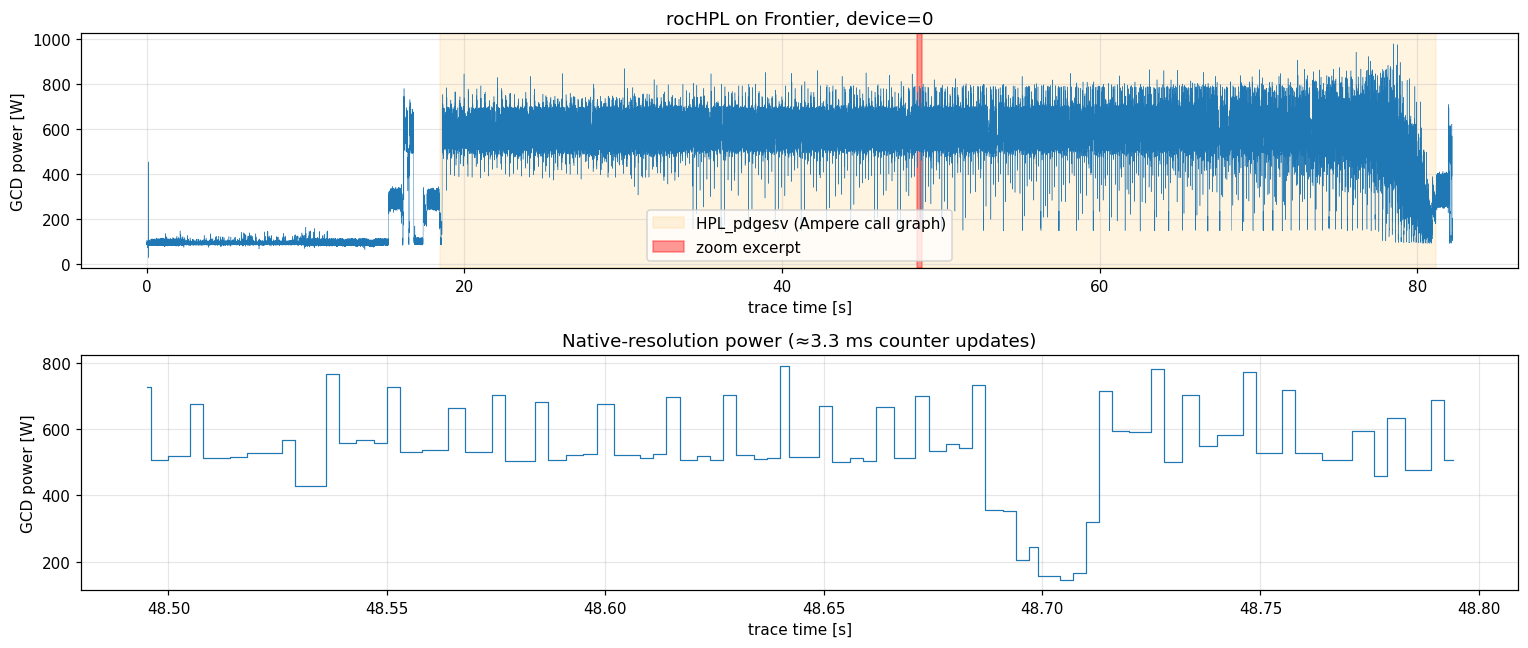

In [38]:
def on_grid(t0, t1, dt=GRID_DT):
    '''Resample GPU power onto a uniform `dt` grid between t0 and t1 (trace seconds).

    The energy counter updates irregularly (about every 3.3 ms), and between updates the power is the
    average dE/dt over that interval. Each 1 ms cell takes the power of the counter interval it falls in.
    The FFT and the square-wave fit need evenly spaced samples, which is why this exists.
    Returns (time since t0 [s], power [W]).
    '''
    g = np.arange(t0, t1, dt)
    idx = np.clip(np.searchsorted(t_E, g, side='right') - 1, 0, len(p_native) - 1)
    return g - t0, p_native[idx]

# The full trace, with t = 0 at the first energy sample
T_START = t_E[0]
G0, G1 = T_GESV0 - T_START, T_GESV1 - T_START            # HPL_pdgesv on the trace clock
tg, pg = on_grid(T_START, t_E[-1])
q_full = pg / A_HEATER_CM2 * 1e4                         # W/m^2
print(f"full trace: {tg[-1]:.1f} s on a {GRID_DT*1e3:.0f} ms grid ({len(tg)} cells); mean flux {q_full.mean()/1e4:.1f} W/cm^2, "
      f"peak {q_full.max()/1e4:.1f} W/cm^2")

ZOOM = (G0 + 30.0, G0 + 30.3)                            # a 300 ms excerpt of the factorization used in the zoomed plots
fig, ax = plt.subplots(2, 1, figsize=(14, 6))
ax[0].plot(t_E[:-1] - T_START, p_native, lw=0.3)
ax[0].axvspan(G0, G1, color='orange', alpha=0.12, label='HPL_pdgesv (Ampere call graph)')
ax[0].axvspan(*ZOOM, color='red', alpha=0.4, label='zoom excerpt')
ax[0].set(ylabel='GCD power [W]', xlabel='trace time [s]', title=f'rocHPL on Frontier, device={DEVICE}'); ax[0].legend(loc='lower center')
sl = (tg >= ZOOM[0]) & (tg < ZOOM[1])
ax[1].step(tg[sl], pg[sl], where='post', lw=0.8)
ax[1].set(xlabel='trace time [s]', ylabel='GCD power [W]', title='Native-resolution power (≈3.3 ms counter updates)')
fig.tight_layout(); fig.savefig(FIG / 'part2_rochpl_power.png', bbox_inches='tight');

**What `on_grid` does:** the energy counter reports at irregular times, about every 3.3 ms (blue bars: one average power per counter interval, with dotted lines at the counter updates). `on_grid` copies those values onto even 1 ms cells (orange), because the FFT and the square-wave fit need evenly spaced samples. It adds no information. Each 1 ms cell repeats the power of the counter interval it falls in.

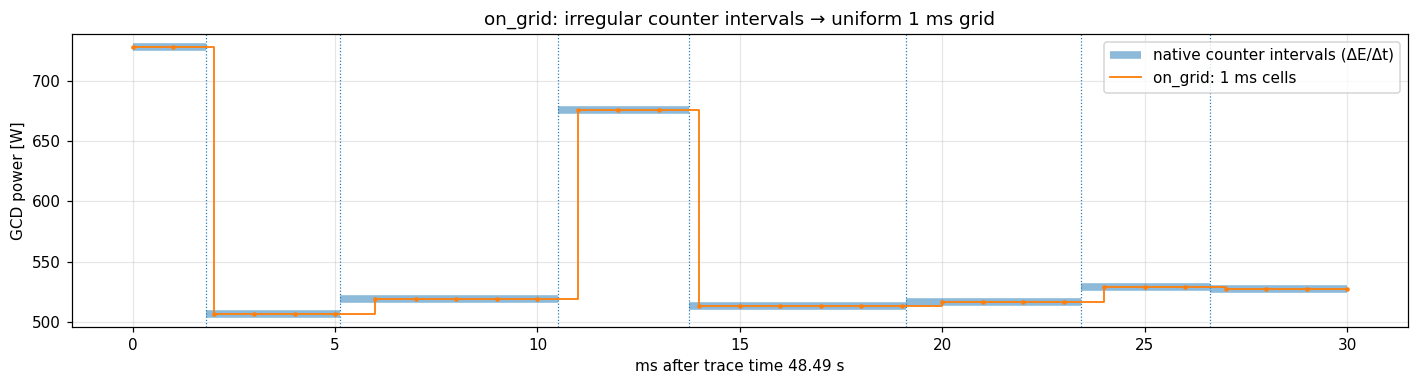

In [39]:
def demo_on_grid():
    s = T_GESV0 + 30.0; e = s + 0.03
    m = (t_E[1:] > s) & (t_E[:-1] < e)
    fig, a = plt.subplots(figsize=(13, 3.6))
    a.hlines(p_native[m], (np.maximum(t_E[:-1][m], s) - s) * 1e3, (np.minimum(t_E[1:][m], e) - s) * 1e3, color='tab:blue', lw=5, alpha=0.5,
             label='native counter intervals (ΔE/Δt)')
    for tb in t_E[(t_E > s) & (t_E < e)]:
        a.axvline((tb - s) * 1e3, color='tab:blue', ls=':', lw=0.8)
    tw, pw = on_grid(s, e)
    a.step(tw * 1e3, pw, where='post', color='tab:orange', lw=1.2, label='on_grid: 1 ms cells')
    a.plot(tw * 1e3, pw, '.', color='tab:orange', ms=4)
    a.set(xlabel=f'ms after trace time {s - T_START:.2f} s', ylabel='GCD power [W]', title='on_grid: irregular counter intervals → uniform 1 ms grid'); a.legend()
    fig.tight_layout(); fig.savefig(FIG / 'howto_on_grid.png', bbox_inches='tight')

demo_on_grid()

## Part 3: Use the FFT to break the full trace into square waves

Square waves aren't an orthogonal basis, so the FFT is used to *choose* each square wave, then each one is fitted (matching pursuit):

1. Take the FFT (Hann window) of the current residual and keep the strongest spectral peaks as candidate frequencies $f_c$.
2. For periods $P$ around $1/f_c$, find the phase $\phi$ and duty cycle $D$ of the square wave $s(t)=\mathbb{1}[(t-\phi) \bmod P < DP]$ that removes the most residual variance. For a zero-mean residual $r$, that reduction is $(\sum_{s=1} r)^2 / (n_{on}(1-n_{on}/N))$. Cumulative sums over the phase-sorted samples give it for every $(\phi, D)$ in closed form. One extra candidate has $P$ equal to the window length. That is a single pulse, which picks up isolated dips and spikes that have no spectral peak.
3. Subtract the best component and repeat $K$ times.
4. Refit all amplitudes and the DC level jointly by least squares: $q''(t) \approx q_0 + \sum_k A_k\, s_k(t)$.

**Short-time decomposition.** rocHPL's rhythm isn't stationary. The DGEMM and panel-broadcast cadence drifts as the trailing matrix shrinks, and there are isolated dips at every panel step. A handful of square waves that run for the whole trace can only follow the slow trend and smear out the ms-scale spikes. So the trace is cut into consecutive windows of `WINDOW_S` (125 ms). Each window gets its own DC level and `K_WINDOW` square waves, and each square wave is switched on at the start of its window and off at the end. A gated square wave is still a sum of flux steps (eq. 32 started at the window start, minus eq. 32 started at the window end), so the superposition argument is unchanged.

Amplitudes can be negative, because a negative square wave is still a valid heat-flux term under linear superposition.

In [40]:
def square(t, P, D, phi):
    '''Unit square wave: 1 while "on", 0 while "off".

    Period P [s], duty cycle D (fraction of each period spent on, 0..1), phase phi [s] (where an on-pulse
    starts). It's on when (t - phi) mod P < D*P. Multiply by an amplitude A to get a heat flux.
    '''
    return (np.mod(t - phi, P) < D * P).astype(float)

def _best_phase_duty(r, t, P, M=96):
    '''For a fixed period P, find the phase and duty cycle of the square wave that best fits residual r.

    "Best" = removes the most variance from r when fitted with its own amplitude (least squares).
    For a square wave that's on at a set of samples S, that variance reduction is
        (sum of r over S)^2 / (n_on * (1 - n_on / n)).
    Every candidate (phase, duty) on an M x (M-1) grid is just a contiguous range of "position within
    the period". So: sort samples by position within the period, take a running sum, and each
    candidate's sum of r is a difference of two running-sum values. All ~9 000 candidates are scored at
    once, without building any of the waves. The range is unrolled twice so pulses that wrap around
    the end of the period are included.
    Returns (variance reduction, phase phi [s], duty D).
    '''
    ph = np.mod(t, P) / P
    o = np.argsort(ph, kind='stable'); phs = ph[o]
    C = np.concatenate([[0.0], np.cumsum(r[o])]); n = len(r)
    idx = np.searchsorted(phs, np.arange(M + 1) / M)
    Cg = np.concatenate([C[idx], C[-1] + C[idx[1:]]])        # unrolled twice to handle wrap-around
    Ng = np.concatenate([idx, n + idx[1:]])
    a = np.arange(M)[:, None]; L = np.arange(1, M)[None, :]
    S = Cg[a + L] - Cg[a]; cnt = (Ng[a + L] - Ng[a]).astype(float)
    with np.errstate(divide='ignore', invalid='ignore'):
        gain = np.where((cnt > 0) & (cnt < n), S * S / (cnt * (1 - cnt / n)), 0.0)
    i, j = np.unravel_index(np.argmax(gain), gain.shape)
    return gain[i, j], i / M * P, (j + 1) / M

def fft_square_wave_decomposition(q, t, dt, K=8, n_candidates=8, period_scan=np.linspace(0.92, 1.08, 17)):
    '''Approximate q(t) as DC + sum of K square waves (greedy "matching pursuit", seeded by the FFT).

    Square waves don't form a clean basis like sines do (no unique "square-wave transform"), so they're
    found greedily, one at a time:
      1. FFT the current residual (what's not explained yet) and take its `n_candidates` strongest peaks.
         A peak at frequency f suggests a repeating pattern with period about 1/f.
      2. For periods near each peak (1/f times each factor in `period_scan`), plus one period equal to
         the whole window (a single pulse, for one-off spikes or dips), let `_best_phase_duty` find the
         best phase and duty. Keep the overall best square wave.
      3. Subtract its least-squares fit from the residual and repeat, K times.
      4. Re-fit the DC level and all K amplitudes together by ordinary least squares, since the waves
         overlap and the greedy amplitudes aren't jointly optimal.
    Returns (DC level, DataFrame of waves [f_fft_Hz, P_s, duty, phase_s, A], per-term contributions
    as an (N, K+1) array whose row sums give the reconstruction).
    '''
    N = len(q)
    f = np.fft.rfftfreq(N, dt); win = np.hanning(N)
    usable = (f > 0) & (f <= 1 / (4 * dt))
    resid = q - q.mean(); comps = []
    for _ in range(K):
        F = np.abs(np.fft.rfft(resid * win)); F[~usable] = 0
        peaks = np.flatnonzero((F[1:-1] > F[:-2]) & (F[1:-1] >= F[2:])) + 1
        cands = peaks[np.argsort(F[peaks])[::-1][:n_candidates]]
        trials = [(P, f[c]) for c in cands for P in period_scan / f[c] if 4 * dt <= P <= 1.5 * t[-1]]
        trials.append((N * dt, 1 / (N * dt)))                  # single pulse within the window
        best = None
        for P, fc in trials:
            g, phi, D = _best_phase_duty(resid, t, P)
            if best is None or g > best[0]:
                best = (g, P, D, phi, fc)
        _, P, D, phi, fc = best
        s0 = square(t, P, D, phi); s0 -= s0.mean()
        if s0 @ s0 > 0:
            resid = resid - (resid @ s0) / (s0 @ s0) * s0
        comps.append(dict(f_fft_Hz=fc, P_s=P, duty=D, phase_s=phi))
    S = np.column_stack([np.ones(N)] + [square(t, c['P_s'], c['duty'], c['phase_s']) for c in comps])
    coef, *_ = np.linalg.lstsq(S, q, rcond=None)
    for c, a in zip(comps, coef[1:]):
        c['A'] = a
    return coef[0], pd.DataFrame(comps), S * coef       # DC, components, per-term contributions (N x K+1)

def windowed_square_wave_decomposition(q, t, dt, W=WINDOW_S, K=K_WINDOW):
    '''Short-time version of `fft_square_wave_decomposition` (like a spectrogram, but with square waves).

    Cuts q into back-to-back windows of W seconds and fits DC + K square waves in each one separately.
    Each wave is "gated": on only inside its own window. This lets the fit follow a rhythm that drifts
    and catch isolated spikes, which a few waves spanning the whole trace can't do.
    Returns (DC level on every grid cell, DataFrame of all waves with their order `k` within the window
    and the window's grid range [i0, i1)).
    '''
    n = int(round(W / dt)); dc = np.empty_like(q); rows = []
    for s in range(0, len(q), n):
        sl = slice(s, s + n); tw = t[sl] - t[s]
        if len(tw) < 4 * K:                                    # short tail: DC only
            dc[sl] = q[sl].mean(); continue
        q0, c, _ = fft_square_wave_decomposition(q[sl], tw, dt, K=K)
        dc[sl] = q0
        rows.append(c.assign(k=np.arange(len(c)), window_start_s=t[s], i0=s, i1=min(s + n, len(q))))   # k: pursuit order
    return dc, pd.concat(rows, ignore_index=True)

def square_wave_flux(comps, t, zero_mean=False):
    '''Rebuild the heat flux [W/m^2] of a set of windowed square waves on the grid t.

    Each row of `comps` adds A * square(...) inside its window [i0, i1). With zero_mean=True each wave's
    average over its window is subtracted, leaving only its up-and-down part (the averages can then be
    accounted for separately as part of the window's mean level).
    '''
    out = np.zeros_like(t)
    for r in comps.itertuples():
        tw = t[r.i0:r.i1] - t[r.i0]
        s = r.A * square(tw, r.P_s, r.duty, r.phase_s)
        out[r.i0:r.i1] += s - s.mean() if zero_mean else s
    return out

### What the square-wave functions do, in pictures

The test signal below is made up so the right answer is known: 30 W/cm² DC, plus a +8 W/cm² wave (P = 23 ms, D = 0.35), a −5 W/cm² wave (P = 9 ms, D = 0.5), a single −15 W/cm² dip 20 ms long, and noise.

1. **`square`**: the three knobs. Period $P$ (how often it repeats), duty $D$ (fraction of each period it is on), phase $\phi$ (where the on-pulse starts).
2. **`_best_phase_duty`**: for one trial period (23 ms), every (phase, duty) pair is scored by how much of the signal's variance a square wave with those settings would explain. The winner is marked with a white ×. There are **two** bright spots because a wave and its complement are equally good. "+8 W/cm², on for 35% of the period" is the same flux as "−8 W/cm², on for the other 65%" plus 8 W/cm² of DC. The fit may return either one, and the amplitude's sign and the DC level absorb the difference.
3. **Why it's fast:** fold the signal by position within the 23 ms period. The 23 ms wave then shows up as a raised band and a low band, and finding the best (phase, duty) means finding where one band starts and how long it is. Running sums over the sorted samples make that cheap. Here the fit took the low band (shaded), i.e. the complement, so its amplitude comes out negative.
4. **`fft_square_wave_decomposition`, step 1**: the FFT of the signal. Red lines mark the frequencies that seeded each pick.
5. **Step 2–3**: the waves it found, in the order it found them, each with its fitted amplitude. Pick 1 is the one-off dip, written as its complement: a +14.7 pulse that is on everywhere *except* the dip. Picks 2 and 3 recover the 23 ms and 9 ms waves (the 23 ms one again as its complement). Pick 4 is a small correction for noise.
6. **Step 4**: DC + those waves (red) over the signal (grey).

true waves (A W/cm², P ms, D, φ ms): [(8.0, 23.0, 0.35, 4.0), (-5.0, 9.0, 0.5, 2.0), (-15.0, 250.0, 0.08, 150.0)]


,P_ms,duty,phase_ms,A
0,250.00,0.92,169.27,14.73
1,22.95,0.60,12.67,-7.81
2,9.02,0.55,1.03,-4.89
3,4.66,0.01,4.61,8.09


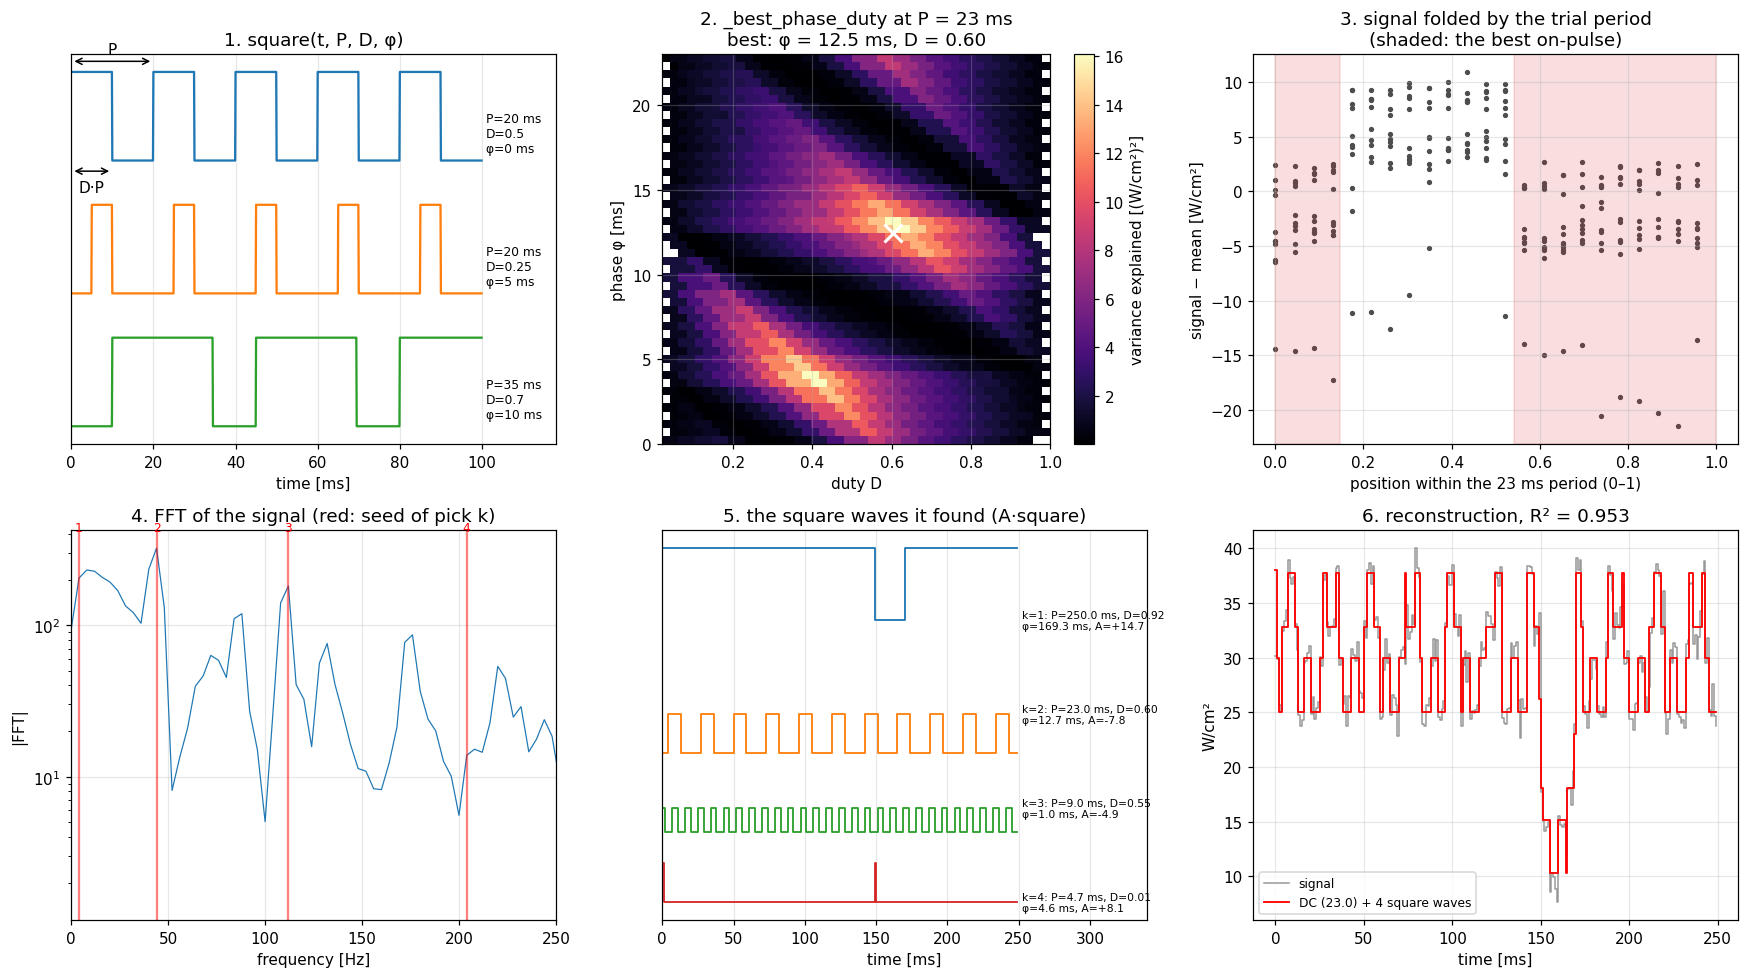

In [41]:
def demo_square_wave_functions():
    dt = 1e-3; t = np.arange(0, 0.25, dt); rng = np.random.default_rng(0)
    truth = [(8.0, 0.023, 0.35, 0.004), (-5.0, 0.009, 0.5, 0.002), (-15.0, 0.25, 0.08, 0.15)]     # A [W/cm^2], P, D, phi
    sig = 30 + sum(A * square(t, P, D, phi) for A, P, D, phi in truth) + rng.normal(0, 1, len(t))
    fig, ax = plt.subplots(2, 3, figsize=(16, 9))

    a = ax[0, 0]; tt = np.arange(0, 0.1, 1e-4)
    for i, (P, D, phi) in enumerate([(0.02, 0.5, 0.0), (0.02, 0.25, 0.005), (0.035, 0.7, 0.01)]):
        a.plot(tt * 1e3, square(tt, P, D, phi) - 1.5 * i, lw=1.5)
        a.text(101, 0.3 - 1.5 * i, f'P={P*1e3:.0f} ms\nD={D}\nφ={phi*1e3:.0f} ms', fontsize=8, va='center')
    a.annotate('', xy=(20, 1.12), xytext=(0, 1.12), arrowprops=dict(arrowstyle='<->')); a.text(10, 1.2, 'P', ha='center')
    a.annotate('', xy=(10, -0.12), xytext=(0, -0.12), arrowprops=dict(arrowstyle='<->')); a.text(5, -0.35, 'D·P', ha='center')
    a.set(xlim=(0, 118), yticks=[], xlabel='time [ms]', title='1. square(t, P, D, φ)')

    r = sig - sig.mean(); P = 0.023; M = 48
    gain = np.full((M, M - 1), np.nan)
    for i in range(M):
        for j in range(1, M):
            sq = square(t, P, j / M, i / M * P); n_on = sq.sum()
            if 0 < n_on < len(t):
                gain[i, j - 1] = (r @ sq) ** 2 / (n_on * (1 - n_on / len(t)))
    g, phi_b, D_b = _best_phase_duty(r, t, P, M)
    a = ax[0, 1]
    im = a.imshow(gain / len(t), origin='lower', aspect='auto', extent=[1 / M, 1, 0, P * 1e3], cmap='magma')
    a.plot(D_b, phi_b * 1e3, 'wx', ms=12, mew=2)
    a.set(xlabel='duty D', ylabel='phase φ [ms]', title=f'2. _best_phase_duty at P = 23 ms\nbest: φ = {phi_b*1e3:.1f} ms, D = {D_b:.2f}')
    fig.colorbar(im, ax=a, label='variance explained [(W/cm²)²]')

    a = ax[0, 2]; pos = np.mod(t, P) / P
    a.scatter(pos, r, s=6, c='0.3')
    lo, hi = phi_b / P, phi_b / P + D_b
    for x0, x1 in ([(lo, hi)] if hi <= 1 else [(lo, 1), (0, hi - 1)]):
        a.axvspan(x0, x1, color='tab:red', alpha=0.15)
    a.set(xlabel='position within the 23 ms period (0–1)', ylabel='signal − mean [W/cm²]', title='3. signal folded by the trial period\n(shaded: the best on-pulse)')

    q0, comps, terms = fft_square_wave_decomposition(sig, t, dt, K=4)
    f = np.fft.rfftfreq(len(t), dt); F = np.abs(np.fft.rfft(r * np.hanning(len(t))))
    a = ax[1, 0]; a.semilogy(f, F, lw=0.8)
    for k, fc in enumerate(comps.f_fft_Hz):
        a.axvline(fc, color='r', alpha=0.5); a.text(fc, F.max() * 1.3, f'{k+1}', color='r', ha='center', fontsize=8)
    a.set(xlim=(0, 250), xlabel='frequency [Hz]', ylabel='|FFT|', title='4. FFT of the signal (red: seed of pick k)')

    a = ax[1, 1]; off = 1.3 * np.abs(terms[:, 1:]).max()
    for k, c in enumerate(comps.itertuples()):
        a.step(t * 1e3, terms[:, k + 1] - k * off, where='post', lw=1.2)
        a.text(252, -k * off, f'k={k+1}: P={c.P_s*1e3:.1f} ms, D={c.duty:.2f}\nφ={c.phase_s*1e3:.1f} ms, A={c.A:+.1f}', fontsize=7, va='center')
    a.set(xlim=(0, 340), yticks=[], xlabel='time [ms]', title='5. the square waves it found (A·square)')

    a = ax[1, 2]; rec = terms.sum(1)
    a.step(t * 1e3, sig, where='post', color='0.6', lw=1, label='signal')
    a.step(t * 1e3, rec, where='post', color='r', lw=1.2, label=f'DC ({q0:.1f}) + 4 square waves')
    a.set(xlabel='time [ms]', ylabel='W/cm²', title=f'6. reconstruction, R² = {1 - np.var(sig - rec) / np.var(sig):.3f}'); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'howto_square_wave_functions.png', bbox_inches='tight')
    print('true waves (A W/cm², P ms, D, φ ms):', [(A, P * 1e3, D, phi * 1e3) for A, P, D, phi in truth])
    display(comps.assign(P_ms=comps.P_s * 1e3, phase_ms=comps.phase_s * 1e3)[['P_ms', 'duty', 'phase_ms', 'A']].round(2))

demo_square_wave_functions()

In [42]:
dc_full, comps_full = windowed_square_wave_decomposition(q_full, tg, GRID_DT)
q_recon = dc_full + square_wave_flux(comps_full, tg)

def r2(x, xhat):
    '''Coefficient of determination: 1 = perfect fit, 0 = no better than a flat line at the mean.'''
    return 1 - np.var(x - xhat) / np.var(x)

def hp(x):
    '''High-pass: x minus its 50 ms moving average, leaving only fluctuations faster than ~50 ms.'''
    return x - uniform_filter1d(x, int(0.05 / GRID_DT))

in_g = (tg >= G0) & (tg < G1)
print(f"{len(comps_full)} square waves in {int(np.ceil(len(tg) * GRID_DT / WINDOW_S))} windows of {WINDOW_S*1e3:.0f} ms")
print(f"flux R^2: full trace {r2(q_full, q_recon):.3f}, HPL_pdgesv {r2(q_full[in_g], q_recon[in_g]):.3f}; "
      f"fluctuations < 50 ms: R^2 = {r2(hp(q_full), hp(q_recon)):.3f}; RMS residual {np.std(q_full - q_recon)/1e4:.2f} W/cm^2")

# Same matching pursuit run once over the whole trace (no windows) for comparison
K_GLOBAL = 16
q0_glob, comps_glob, terms_glob = fft_square_wave_decomposition(q_full, tg, GRID_DT, K=K_GLOBAL)
print(f"global DC + {K_GLOBAL} square waves (no windows): flux R^2 {r2(q_full, terms_glob.sum(1)):.3f}, "
      f"fluctuations < 50 ms: R^2 = {r2(hp(q_full), hp(terms_glob.sum(1))):.3f}")

comps_full.drop(columns=['i0', 'i1']).assign(P_ms=comps_full.P_s * 1e3, A_W_cm2=comps_full.A / 1e4) \
    .to_csv(OUT / 'full_trace_square_waves.csv', index=False)

7896 square waves in 658 windows of 125 ms
flux R^2: full trace 0.988, HPL_pdgesv 0.954; fluctuations < 50 ms: R^2 = 0.935; RMS residual 1.56 W/cm^2
global DC + 16 square waves (no windows): flux R^2 0.789, fluctuations < 50 ms: R^2 = -0.001


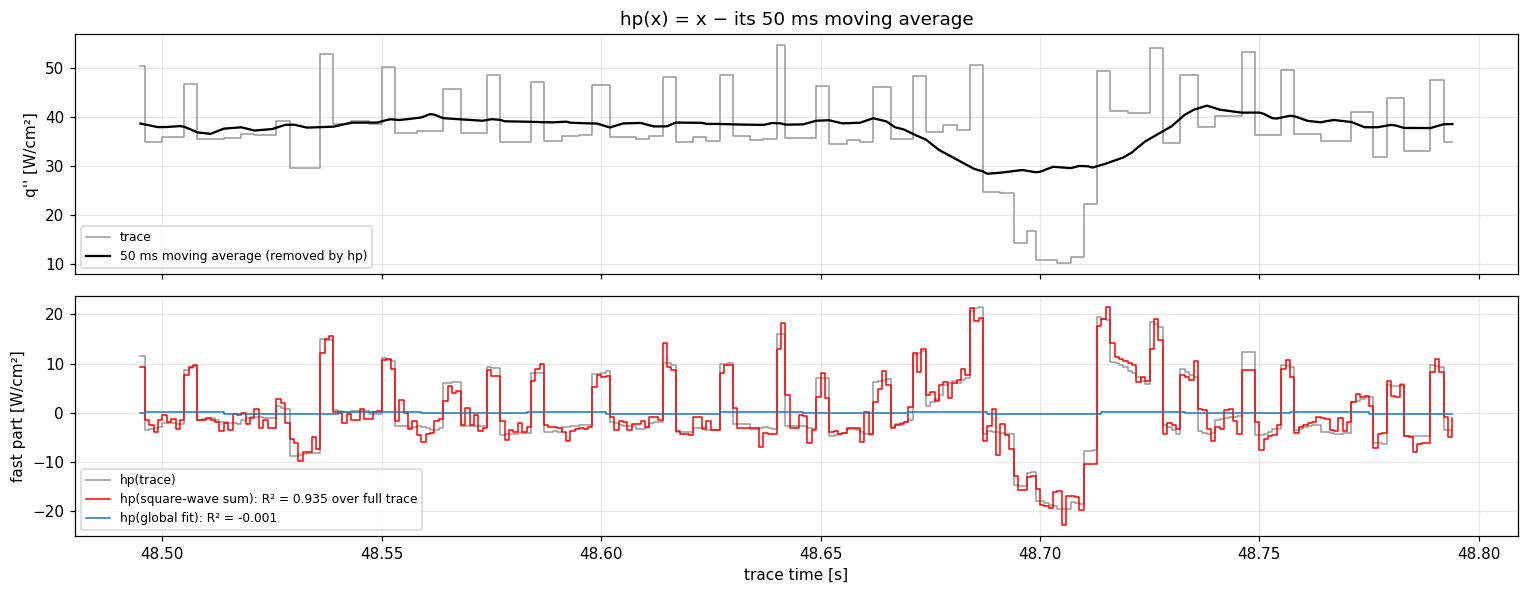

In [43]:
# What hp() and r2() measure: hp keeps only the fast (< ~50 ms) wiggles, which is what the
# "fluctuations < 50 ms" R^2 scores. Without it, the slow envelope would make any fit look good.
def demo_hp():
    sl = (tg >= ZOOM[0]) & (tg < ZOOM[1])
    fig, ax = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
    ax[0].step(tg[sl], q_full[sl] / 1e4, where='post', color='0.6', lw=1, label='trace')
    ax[0].plot(tg[sl], uniform_filter1d(q_full, int(0.05 / GRID_DT))[sl] / 1e4, color='k', lw=1.5, label='50 ms moving average (removed by hp)')
    ax[0].set(ylabel="q'' [W/cm²]", title='hp(x) = x − its 50 ms moving average'); ax[0].legend(fontsize=8)
    ax[1].step(tg[sl], hp(q_full)[sl] / 1e4, where='post', color='0.6', lw=1, label='hp(trace)')
    ax[1].step(tg[sl], hp(q_recon)[sl] / 1e4, where='post', color='r', lw=1, label=f'hp(square-wave sum): R² = {r2(hp(q_full), hp(q_recon)):.3f} over full trace')
    ax[1].step(tg[sl], hp(terms_glob.sum(1))[sl] / 1e4, where='post', color='tab:blue', lw=1, label=f'hp(global fit): R² = {r2(hp(q_full), hp(terms_glob.sum(1))):.3f}')
    ax[1].set(xlabel='trace time [s]', ylabel="fast part [W/cm²]"); ax[1].legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'howto_hp_r2.png', bbox_inches='tight')

demo_hp()

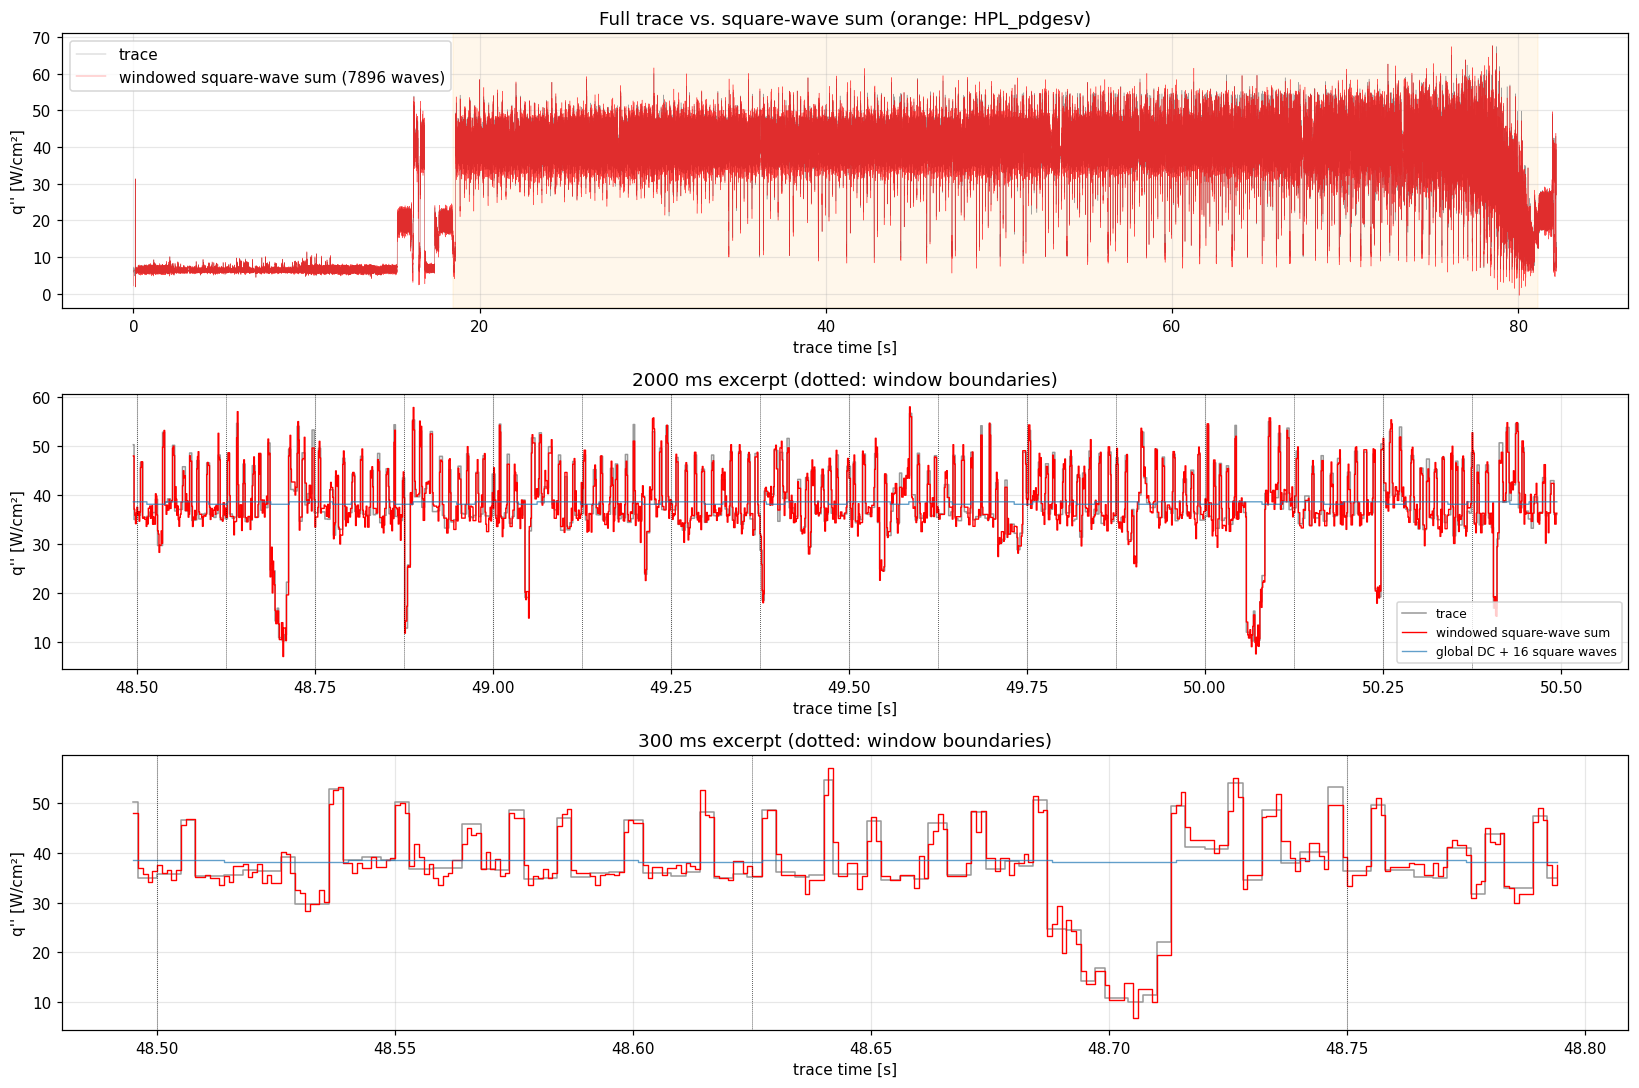

In [44]:
fig, ax = plt.subplots(3, 1, figsize=(15, 10))
ax[0].plot(tg, q_full / 1e4, color='0.6', lw=0.3, label='trace')
ax[0].plot(tg, q_recon / 1e4, color='r', lw=0.3, alpha=0.7, label=f'windowed square-wave sum ({len(comps_full)} waves)')
ax[0].axvspan(G0, G1, color='orange', alpha=0.08)
ax[0].set(xlabel='trace time [s]', ylabel="q'' [W/cm²]", title='Full trace vs. square-wave sum (orange: HPL_pdgesv)'); ax[0].legend(loc='upper left')
for a, (s, e) in zip(ax[1:], [(G0 + 30, G0 + 32), ZOOM]):
    sl = (tg >= s) & (tg < e)
    a.step(tg[sl], q_full[sl] / 1e4, where='post', color='0.6', lw=1, label='trace')
    a.step(tg[sl], q_recon[sl] / 1e4, where='post', color='r', lw=0.9, label='windowed square-wave sum')
    a.step(tg[sl], terms_glob.sum(1)[sl] / 1e4, where='post', color='tab:blue', lw=0.9, alpha=0.7, label=f'global DC + {K_GLOBAL} square waves')
    for wb in np.arange(np.ceil(s / WINDOW_S), e / WINDOW_S) * WINDOW_S:
        a.axvline(wb, color='k', lw=0.5, ls=':')
    a.set(xlabel='trace time [s]', ylabel="q'' [W/cm²]", title=f'{(e-s)*1e3:.0f} ms excerpt (dotted: window boundaries)')
ax[1].legend(loc='lower right', fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'part3_full_trace_decomposition.png', bbox_inches='tight');

### How the approximation emerges from the square waves

The 300 ms excerpt below is built up one square wave at a time, in the order the matching pursuit picked them in each window ($k$ = 1 is the first pick).

* **Left:** each window's mean flux, then the $k$-th square wave of every window. The amplitude $A_k$ and the window gating are included, and the wave's in-window mean is removed (that mean is already part of the window mean). Each window picks a different period, duty and phase, so wave $k$ changes character at every dotted window boundary.
* **Middle:** the running sum, window mean + waves $1..k$ (red), over the trace (grey). The first few picks take care of the largest features, such as the panel-step dip and the DGEMM bursts. Later picks add finer, shorter spikes.
* **Right:** how $R^2$ grows with $k$, over the full trace and for the fluctuations faster than 50 ms.

Amplitudes are the final joint least-squares values, so a partial sum isn't exactly what the pursuit had after $k$ steps. It still shows what each wave contributes. With all $k$ = 12 waves the sum is exactly the reconstruction used in Part 4.

k                  0      1      2      3      4      5      6      7      8      9      10     11     12
R2_full         0.796  0.885  0.915  0.934  0.948  0.957  0.965  0.971  0.976  0.980  0.983  0.986  0.988
R2_fast_lt50ms -0.002  0.381  0.543  0.642  0.711  0.766  0.808  0.841  0.867  0.889  0.907  0.923  0.935
R2_excerpt      0.019  0.628  0.703  0.776  0.818  0.849  0.871  0.894  0.907  0.921  0.933  0.943  0.953


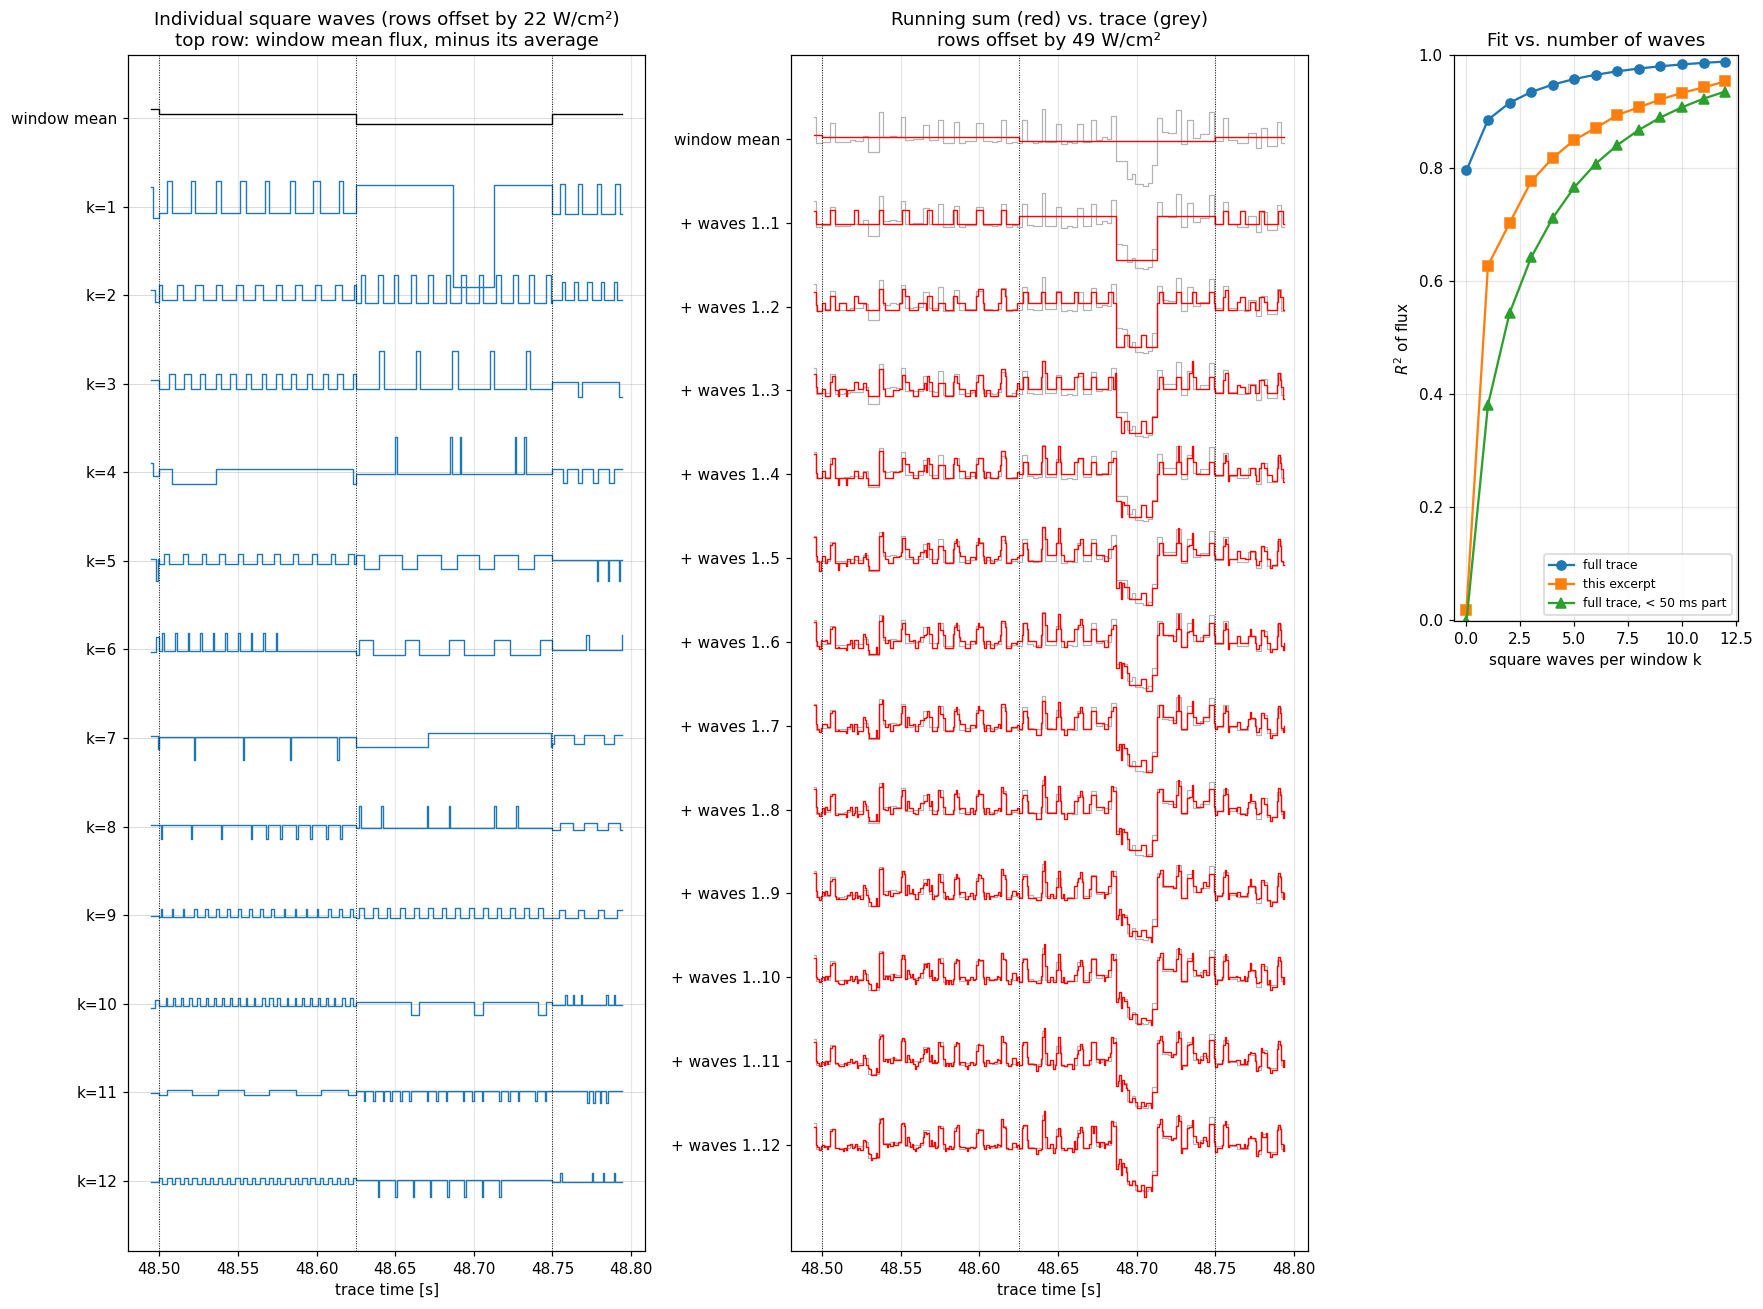

In [45]:
sl = (tg >= ZOOM[0]) & (tg < ZOOM[1]); ts = tg[sl]
ia, ib = np.flatnonzero(sl)[[0, -1]]
ex = comps_full[(comps_full.i1 > ia) & (comps_full.i0 <= ib)]
waves = [square_wave_flux(ex[ex.k == k], tg, zero_mean=True)[sl] for k in range(K_WINDOW)]
win_mean = q_recon - square_wave_flux(comps_full, tg, zero_mean=True)     # each window's mean flux
partial = np.cumsum([win_mean[sl]] + waves, axis=0)

fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.55], height_ratios=[1, 1])
a0, a1, a2 = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[:, 1]), fig.add_subplot(gs[0, 2])
d0 = 1.1 * max(np.abs(np.concatenate(waves)).max(), np.ptp(win_mean[sl])) / 1e4; d1 = 1.1 * np.ptp(q_full[sl]) / 1e4
for k in range(K_WINDOW + 1):
    y0 = (win_mean[sl] - win_mean[sl].mean()) if k == 0 else waves[k - 1]
    a0.step(ts, y0 / 1e4 - k * d0, where='post', color='tab:blue' if k else 'k', lw=0.9)
    a0.axhline(-k * d0, color='0.85', lw=0.6, zorder=0)
    c1 = q_full[sl].mean()
    a1.step(ts, (q_full[sl] - c1) / 1e4 - k * d1, where='post', color='0.7', lw=0.8)
    a1.step(ts, (partial[k] - c1) / 1e4 - k * d1, where='post', color='r', lw=0.9)
labels = ['window mean'] + [f'k={k}' for k in range(1, K_WINDOW + 1)]
for a, d, lab in [(a0, d0, labels), (a1, d1, ['window mean'] + [f'+ waves 1..{k}' for k in range(1, K_WINDOW + 1)])]:
    a.set_yticks(-np.arange(K_WINDOW + 1) * d); a.set_yticklabels(lab); a.grid(axis='y', visible=False)
    for wb in np.arange(np.ceil(ZOOM[0] / WINDOW_S), ZOOM[1] / WINDOW_S) * WINDOW_S:
        a.axvline(wb, color='k', lw=0.6, ls=':')
    a.set_xlabel('trace time [s]')
a0.set_title(f'Individual square waves (rows offset by {d0:.0f} W/cm²)\ntop row: window mean flux, minus its average')
a1.set_title(f'Running sum (red) vs. trace (grey)\nrows offset by {d1:.0f} W/cm²')

r2_k = []
for k in range(K_WINDOW + 1):
    qk = win_mean + square_wave_flux(comps_full[comps_full.k < k], tg, zero_mean=True)
    r2_k.append((r2(q_full, qk), r2(hp(q_full), hp(qk)), r2(q_full[sl], qk[sl])))
r2_k = np.array(r2_k)
a2.plot(range(K_WINDOW + 1), r2_k[:, 0], 'o-', label='full trace')
a2.plot(range(K_WINDOW + 1), r2_k[:, 2], 's-', label='this excerpt')
a2.plot(range(K_WINDOW + 1), r2_k[:, 1], '^-', label='full trace, < 50 ms part')
a2.set(xlabel='square waves per window k', ylabel='$R^2$ of flux', title='Fit vs. number of waves', ylim=(min(0, r2_k.min()), 1)); a2.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'part3_square_wave_buildup.png', bbox_inches='tight')
print(pd.DataFrame(r2_k, columns=['R2_full', 'R2_fast_lt50ms', 'R2_excerpt']).rename_axis('k').round(3).T.to_string())

### The square-wave components of one window, and how they interact

This zooms in on a single 125 ms window, the one with the panel-step dip, and shows all 12 of its square waves as fitted (raw, with the window's DC level kept separate):

* **Left:** each wave on its own row. Red waves have positive amplitude: they *add* flux while on. Blue waves have negative amplitude: they *remove* flux while on. The label gives period, duty, phase and amplitude.
* **Right, top:** when each wave is on and by how much (rows = waves, colour = signed contribution). Read a column top to bottom to see which waves are active at that instant.
* **Right, middle:** how they stack. Starting from the DC level (dashed), each wave is a coloured layer. Positive waves stack upward, negative waves stack downward, and the black line is the net. At any instant, the flux is the DC plus the height of every layer that's on.

Things to notice in this window:
* The DC is *negative* (−3.6 W/cm²). It's not the average power, it's the level when every wave is off, which never happens here. Only the sum is meaningful.
* Wave 1 is a 125 ms single pulse that's on everywhere except the panel-step dip. The fit builds the dip by *switching a big wave off*, and the other waves stack the DGEMM bursts on top.
* Short-period waves with small duty (k = 4, 8) add the narrowest spikes. Long-duty waves (k = 11, 12) add a near-constant level with regular notches. Where several waves line up you get the tallest peaks. In other windows, negative waves carve notches out of positive ones in the same way.
* **Right, bottom:** the net sum against the measured trace.

,k,f_fft_Hz,P_ms,duty,phase_ms,A_W_cm2
4668,0,8.0,125.00,0.79,87.24,25.26
4669,1,96.0,10.73,0.28,2.46,6.94
4670,2,40.0,23.25,0.15,14.29,9.36
4671,3,176.0,5.85,0.04,1.46,9.09
4672,4,40.0,24.50,0.59,14.04,3.48
4673,5,32.0,28.75,0.32,1.50,3.68
4674,6,8.0,125.00,0.62,45.57,3.56
4675,7,72.0,14.31,0.04,1.64,5.31
4676,8,112.0,8.75,0.31,1.55,2.59
4677,9,24.0,40.42,0.86,40.00,3.26


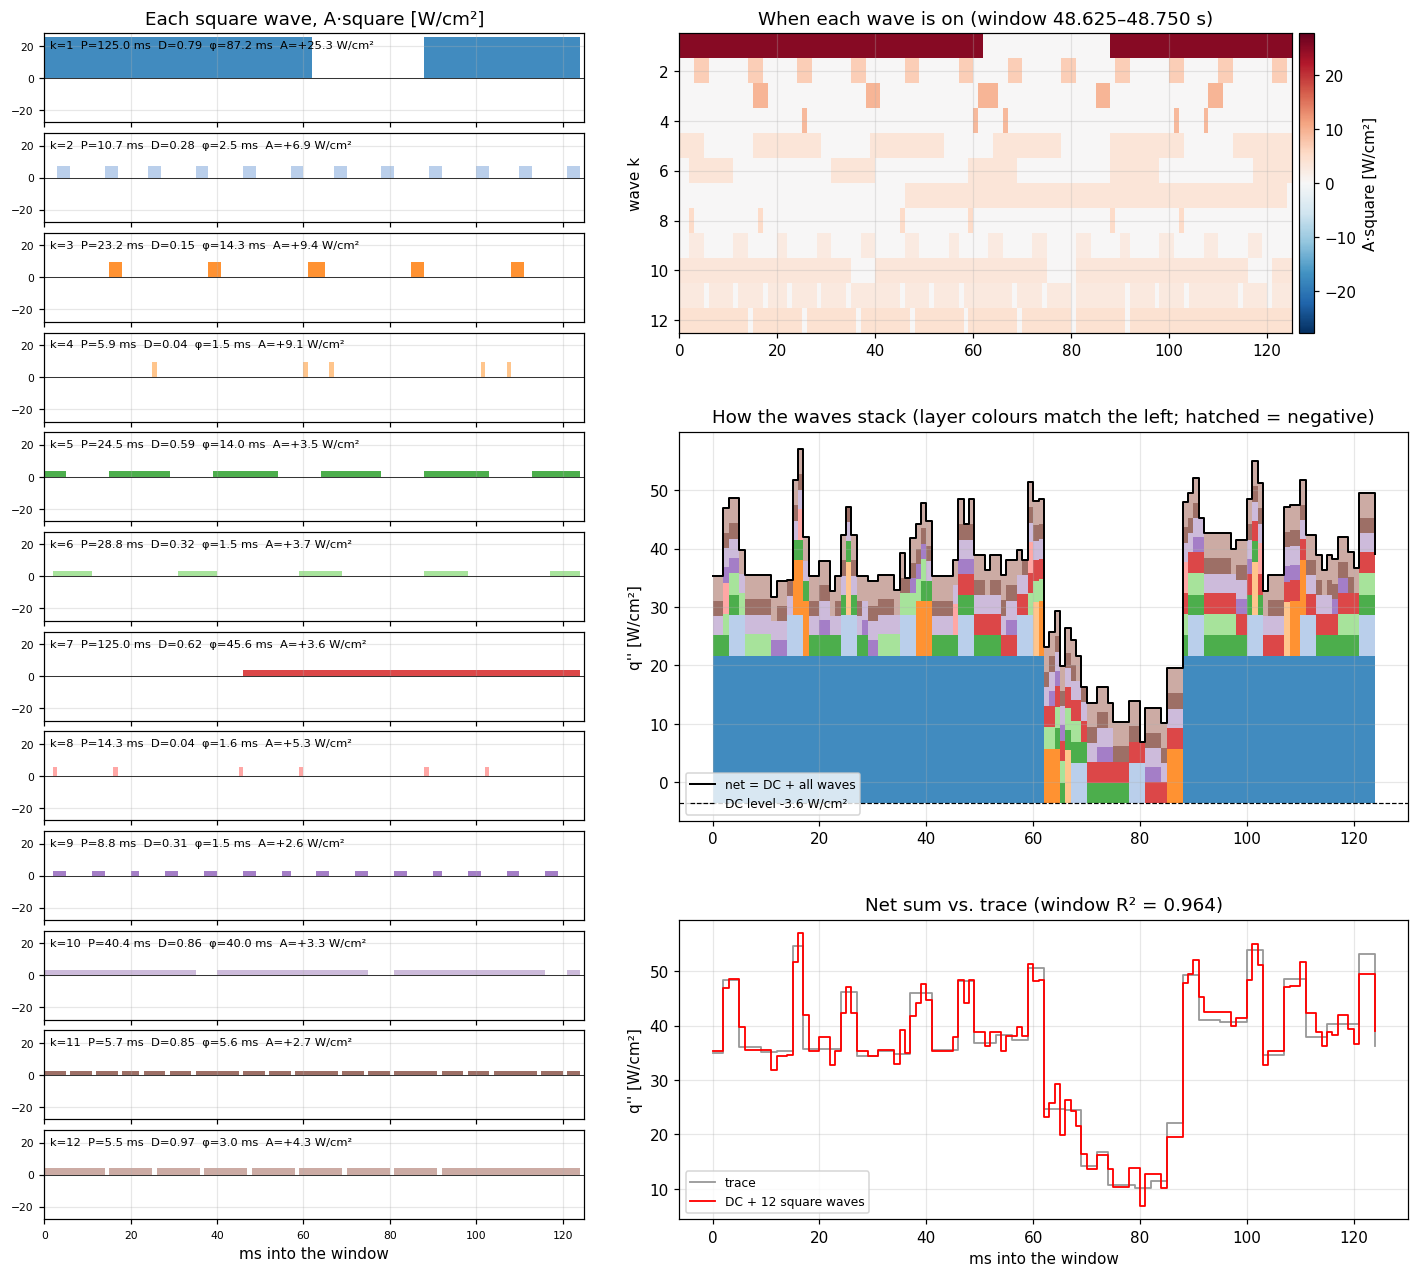

In [46]:
def demo_window_components(t_in=ZOOM[0] + 0.2):
    n = int(round(WINDOW_S / GRID_DT)); i0 = (int(round(t_in / GRID_DT)) // n) * n
    w = comps_full[comps_full.i0 == i0].sort_values('k'); i1 = int(w.i1.iloc[0])
    ts = tg[i0:i1] - tg[i0]; tms = ts * 1e3
    waves = np.array([r.A * square(ts, r.P_s, r.duty, r.phase_s) for r in w.itertuples()]) / 1e4   # W/cm^2
    dc = dc_full[i0] / 1e4; net = dc + waves.sum(0)
    lim = np.abs(waves).max() * 1.1
    colors = plt.cm.tab20(np.arange(len(w)) % 20)

    fig = plt.figure(figsize=(16, 14))
    outer = fig.add_gridspec(1, 2, width_ratios=[1, 1.35], wspace=0.15)
    left = outer[0].subgridspec(len(w), 1, hspace=0.12)
    right = outer[1].subgridspec(3, 1, height_ratios=[1, 1.3, 1], hspace=0.3)
    for k, r in enumerate(w.itertuples()):
        a = fig.add_subplot(left[k])
        a.fill_between(tms, waves[k], step='post', color=colors[k], alpha=0.85, lw=0)
        a.axhline(0, color='k', lw=0.5)
        a.text(0.01, 0.92, f'k={k+1}  P={r.P_s*1e3:.1f} ms  D={r.duty:.2f}  φ={r.phase_s*1e3:.1f} ms  A={r.A/1e4:+.1f} W/cm²',
               transform=a.transAxes, fontsize=7.5, va='top')
        a.set(ylim=(-lim, lim), xlim=(0, tms[-1] + 1)); a.tick_params(labelsize=7)
        if k < len(w) - 1: a.set_xticklabels([])
        if k == 0: a.set_title('Each square wave, A·square [W/cm²]')
    a.set_xlabel('ms into the window')

    a = fig.add_subplot(right[0])
    im = a.pcolormesh(np.append(tms, tms[-1] + 1), np.arange(len(w) + 1) + 0.5, waves, cmap='RdBu_r', vmin=-lim, vmax=lim, shading='flat')
    a.set(ylabel='wave k', title=f'When each wave is on (window {tg[i0]:.3f}–{tg[i1-1]+GRID_DT:.3f} s)'); a.invert_yaxis()
    fig.colorbar(im, ax=a, label='A·square [W/cm²]', pad=0.01)
    a = fig.add_subplot(right[1])
    up = np.full_like(tms, dc); dn = np.full_like(tms, dc)
    for k in range(len(w)):
        h = waves[k]
        if w.A.iloc[k] >= 0:
            a.fill_between(tms, up, up + h, step='post', color=colors[k], alpha=0.85, lw=0); up = up + h
        else:
            a.fill_between(tms, dn + h, dn, step='post', color=colors[k], alpha=0.85, lw=0, hatch='//'); dn = dn + h
    a.step(tms, net, where='post', color='k', lw=1.3, label='net = DC + all waves')
    a.axhline(dc, color='k', ls='--', lw=0.8, label=f'DC level {dc:+.1f} W/cm²')
    a.set(ylabel="q'' [W/cm²]", title='How the waves stack (layer colours match the left; hatched = negative)'); a.legend(fontsize=8, loc='lower left')
    a = fig.add_subplot(right[2])
    a.step(tms, q_full[i0:i1] / 1e4, where='post', color='0.6', lw=1.2, label='trace')
    a.step(tms, net, where='post', color='r', lw=1.2, label=f'DC + {len(w)} square waves')
    a.set(xlabel='ms into the window', ylabel="q'' [W/cm²]", title=f'Net sum vs. trace (window R² = {r2(q_full[i0:i1] / 1e4, net):.3f})'); a.legend(fontsize=8)
    fig.savefig(FIG / 'part3_window_components.png', bbox_inches='tight')
    display(w.assign(P_ms=w.P_s * 1e3, phase_ms=w.phase_s * 1e3, A_W_cm2=w.A / 1e4)[['k', 'f_fft_Hz', 'P_ms', 'duty', 'phase_ms', 'A_W_cm2']].round(2))

demo_window_components()

## Part 4: Cooling response over the full trace, with the model applied to each square wave

Every square wave (and every window's DC level) is a set of flux steps. Its response is the eq. 26 step response superposed (eq. 32 for a single wave), starting from saturated liquid at $t=0$, which is the derivation's initial condition. The total response is the sum of the component responses. It is checked against the model driven directly by the measured trace.

The ≈8 000 components are summed in **period bands**, and each band's response is computed. Because the model is linear, that equals the sum of the individual responses, and it shows which time scales set the wall temperature. Each square wave's in-window mean is moved into the "window mean levels" band (the 125 ms staircase of the run's envelope). The square-wave bands are then pure fluctuations, and the total is unchanged.

In [47]:
# Check the FFT-convolution evaluator against direct step superposition on the first 2 s
n_chk = int(2.0 / GRID_DT)
tj_c, dq_c = steps_from_grid(q_full[:n_chk], GRID_DT)
direct = theta_steps(np.array([0.0, 20e-6])[:, None], tg[None, :n_chk], tj_c, dq_c)
print("max |theta_grid - theta_steps| over 2 s:", np.abs(theta_grid(q_full[:n_chk], GRID_DT, [0.0, 20e-6]) - direct).max(), "K")

# Wall superheat: model driven by the trace, by the square-wave sum, and per period band
bands = {'P > 50 ms': (0.05, np.inf), '10–50 ms': (0.01, 0.05), 'P < 10 ms': (0, 0.01)}
band_flux = {name: square_wave_flux(comps_full[(comps_full.P_s >= lo) & (comps_full.P_s < hi)], tg, zero_mean=True)
             for name, (lo, hi) in bands.items()}
band_flux = {'window mean levels': q_recon - sum(band_flux.values()), **band_flux}
band_wall = {k: theta_grid(v, GRID_DT, [0.0])[0] for k, v in band_flux.items()}
wall_sw = sum(band_wall.values())
wall_trace = theta_grid(q_full, GRID_DT, [0.0])[0]
wall_glob = theta_grid(terms_glob.sum(1), GRID_DT, [0.0])[0]

err = wall_sw - wall_trace
print(f"wall superheat at end of trace: trace {wall_trace[-1]:.0f} K, square-wave sum {wall_sw[-1]:.0f} K")
print(f"square-wave sum vs trace, wall: RMS {np.sqrt(np.mean(err**2)):.2f} K, max {np.abs(err).max():.2f} K; "
      f"fast (<50 ms) wall ripple R^2 = {r2(hp(wall_trace), hp(wall_sw)):.3f} (global fit: {r2(hp(wall_trace), hp(wall_glob)):.3f})")
print(f"fast wall ripple RMS during HPL_pdgesv: trace {np.std(hp(wall_trace)[in_g]):.2f} K, windowed sum {np.std(hp(wall_sw)[in_g]):.2f} K, "
      f"global fit {np.std(hp(wall_glob)[in_g]):.2f} K")

max |theta_grid - theta_steps| over 2 s: 8.872145812688359e-06 K
wall superheat at end of trace: trace 8499 K, square-wave sum 8499 K
square-wave sum vs trace, wall: RMS 1.94 K, max 13.64 K; fast (<50 ms) wall ripple R^2 = 0.970 (global fit: -0.002)
fast wall ripple RMS during HPL_pdgesv: trace 10.91 K, windowed sum 10.70 K, global fit 0.74 K


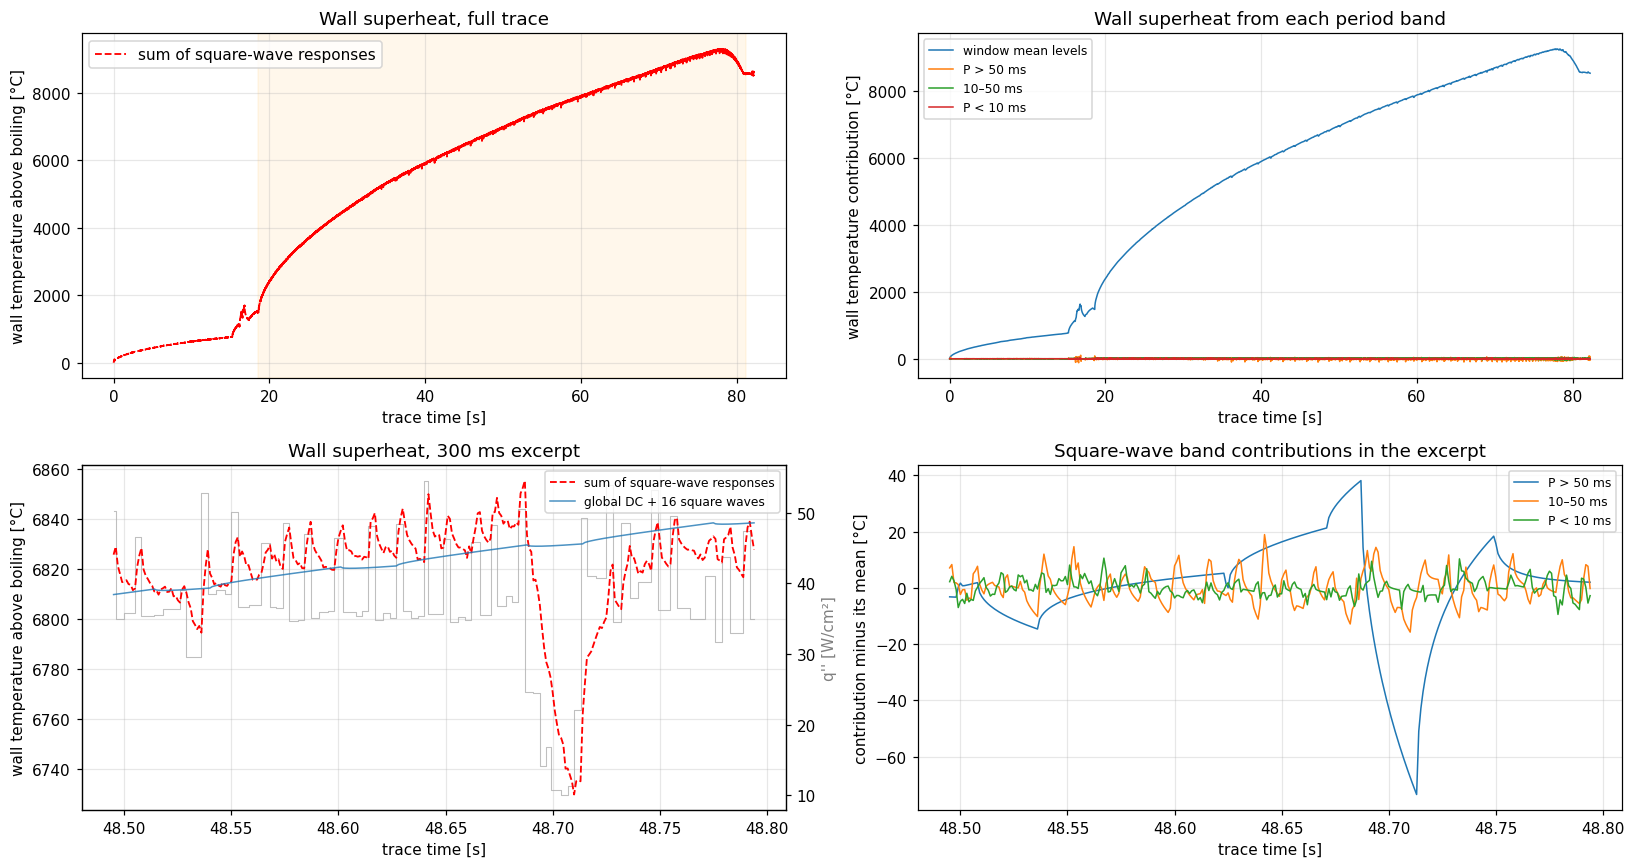

In [48]:
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
a = ax[0, 0]
# a.plot(tg, wall_trace, 'k', lw=2, label='model driven by trace')
a.plot(tg, wall_sw, 'r--', lw=1.2, label='sum of square-wave responses')
a.axvspan(G0, G1, color='orange', alpha=0.08)
a.set(xlabel='trace time [s]', ylabel='wall temperature above boiling [°C]', title='Wall superheat, full trace'); a.legend()
a = ax[0, 1]
for k, w in band_wall.items():
    a.plot(tg, w, lw=1, label=k)
a.set(xlabel='trace time [s]', ylabel='wall temperature contribution [°C]', title='Wall superheat from each period band'); a.legend(fontsize=8)
sl = (tg >= ZOOM[0]) & (tg < ZOOM[1])
a = ax[1, 0]
# a.plot(tg[sl], wall_trace[sl], 'k', lw=2, label='model driven by trace')
a.plot(tg[sl], wall_sw[sl], 'r--', lw=1.2, label='sum of square-wave responses')
a.plot(tg[sl], wall_glob[sl], color='tab:blue', lw=1, alpha=0.8, label=f'global DC + {K_GLOBAL} square waves')
a.set(xlabel='trace time [s]', ylabel='wall temperature above boiling [°C]', title='Wall superheat, 300 ms excerpt'); a.legend(fontsize=8)
b = a.twinx(); b.step(tg[sl], q_full[sl] / 1e4, color='0.75', where='post', lw=0.7, zorder=0); b.set_ylabel("q'' [W/cm²]", color='0.5'); b.grid(False)
a.set_zorder(b.get_zorder() + 1); a.patch.set_visible(False)
a = ax[1, 1]
for k, w in list(band_wall.items())[1:]:
    a.plot(tg[sl], w[sl] - w[sl].mean(), lw=1, label=k)
a.set(xlabel='trace time [s]', ylabel='contribution minus its mean [°C]', title='Square-wave band contributions in the excerpt'); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'part4_full_trace_wall.png', bbox_inches='tight');

fast (<50 ms) ripple during HPL_pdgesv: 10.70 K RMS at the wall, falls to 10% by y = 59 um


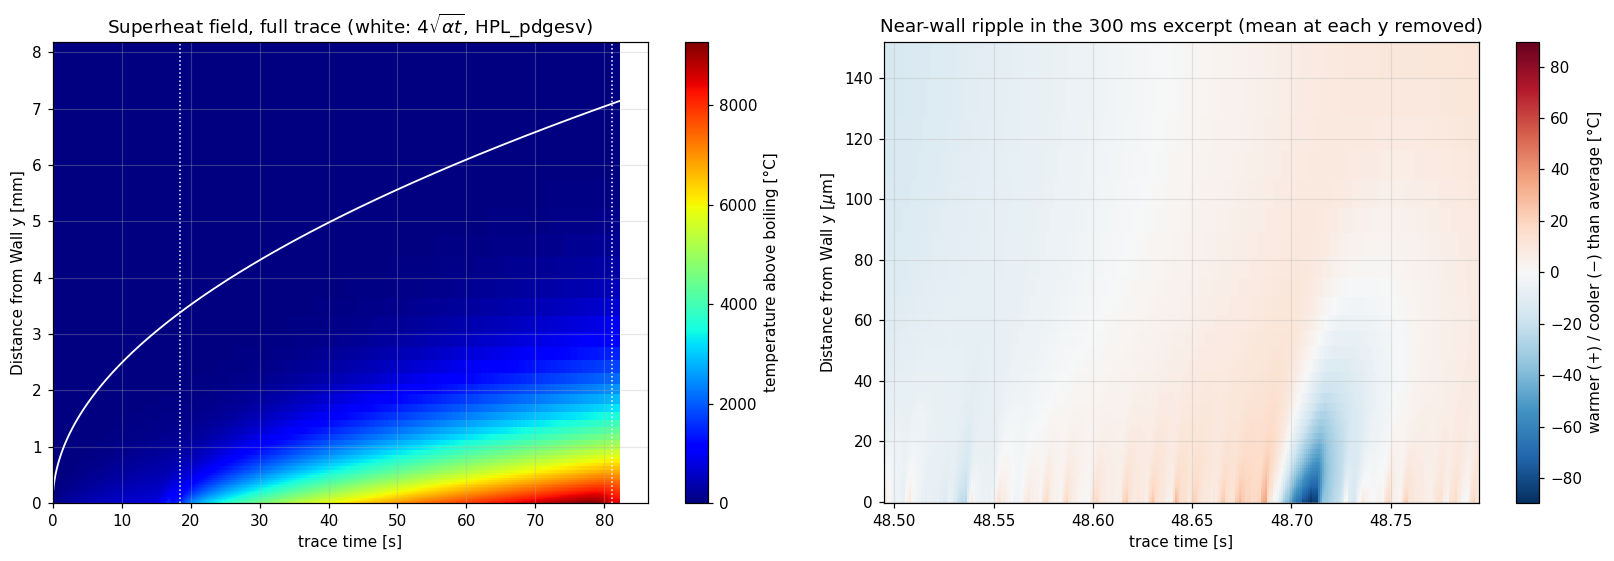

In [49]:
# Superheat field from the square-wave sum. A log-spaced y grid covers both the ms-scale near-wall ripple and the
# multi-mm layer that grows over the full run.
y_f = np.concatenate([[0.0], np.geomspace(1e-6, 1.1 * 4 * np.sqrt(ALPHA * tg[-1]), 100)])
field_sw = theta_grid(q_recon, GRID_DT, y_f)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
step = 20                                                    # 20 ms columns for the full-run heatmap
im = ax[0].pcolormesh(tg[::step], y_f * 1e3, field_sw[:, ::step], cmap='jet', shading='auto', vmin=0)
ax[0].plot(tg, 4 * np.sqrt(ALPHA * tg) * 1e3, 'w', lw=1.2)
ax[0].axvline(G0, color='w', ls=':', lw=1); ax[0].axvline(G1, color='w', ls=':', lw=1)
ax[0].set(xlabel='trace time [s]', ylabel='Distance from Wall y [mm]', title=r'Superheat field, full trace (white: $4\sqrt{\alpha t}$, HPL_pdgesv)')
fig.colorbar(im, ax=ax[0], label='temperature above boiling [°C]')
sl = (tg >= ZOOM[0]) & (tg < ZOOM[1]); ny = np.searchsorted(y_f, 150e-6)
dev = field_sw[:ny, sl] - field_sw[:ny, sl].mean(1, keepdims=True)
lim = np.abs(dev).max()
im = ax[1].pcolormesh(tg[sl], y_f[:ny] * 1e6, dev, cmap='RdBu_r', shading='auto', vmin=-lim, vmax=lim)
ax[1].set(xlabel='trace time [s]', ylabel=r'Distance from Wall y [$\mu$m]', title='Near-wall ripple in the 300 ms excerpt (mean at each y removed)')
fig.colorbar(im, ax=ax[1], label='warmer (+) / cooler (−) than average [°C]')
fig.tight_layout(); fig.savefig(FIG / 'part4_full_trace_field.png', bbox_inches='tight')

# How deep the ripple reaches: RMS of the fast fluctuation vs. depth
rip = np.std(hp(field_sw[:, in_g]), axis=1)
d10 = y_f[np.argmax(rip < 0.1 * rip[0])]
print(f"fast (<50 ms) ripple during HPL_pdgesv: {rip[0]:.2f} K RMS at the wall, falls to 10% by y = {d10*1e6:.0f} um")

In [50]:
# Time for the wall to reach given superheats (pre-nucleation): compare these to your measured
# onset-of-nucleate-boiling superheat for the coolant/surface.
rows = []
for thr in [5, 10, 20, 50, 100, 200]:
    hit = lambda w: tg[np.argmax(w >= thr)] if (w >= thr).any() else np.nan
    rows.append(dict(superheat_K=thr, t_trace_s=hit(wall_trace), t_square_waves_s=hit(wall_sw)))
display(pd.DataFrame(rows).round(3))

,superheat_K,t_trace_s,t_square_waves_s
0,5,0.001,0.002
1,10,0.003,0.004
2,20,0.011,0.012
3,50,0.066,0.068
4,100,0.109,0.109
5,200,1.066,1.076


### What the full-trace result means

* The windowed square-wave sum follows the trace spike for spike: flux R² ≈ 0.99 over the full trace, and ≈0.93 for the sub-50 ms fluctuations alone. Isolated panel-step dips (down to ≈10 W/cm²) and the 50–55 W/cm² DGEMM bursts both survive. The same matching pursuit run once over the whole trace stays at the mean, so its fast-fluctuation R² is ≈0.
* The wall superheat from the square-wave sum matches the trace-driven model, including its fast ripple. During `HPL_pdgesv` that ripple is ≈11 K RMS (fast-ripple R² ≈ 0.97), with ≈100 K dips at the long panel-step stalls. The global fit gives under 1 K. The ripple only reaches a thin layer: it falls to 10% within ≈60 µm of the wall.
* The level of $\Theta_w$ is set by the window mean levels, which are the slow envelope of the run. Conduction-only heating from saturation grows like $\sqrt{t}$ with no heat sink, so the wall reaches hundreds of kelvin within seconds and thousands by the end of the run. That isn't physical: once nucleation starts, boiling and convection remove the mean flux. Long-horizon predictions need the next step of the model (a boiling or convective sink). These results stay valid for the pre-nucleation transient (see the time-to-superheat table) and for the ripple that the fast square waves impose on top of whatever mean temperature the wall settles at.

## Part 5: Square-wave catalogue for the full trace

For each square wave the model gives the **periodic steady-state swing** of wall superheat once the √t growth from its mean flux is removed. For a semi-infinite liquid, each Fourier harmonic gives $\hat\Theta_w = \hat q''/(e\sqrt{i\omega})$. The windowed waves only run for 125 ms, so for the longer periods this is an upper bound. The cluster at ≈125 ms is the single-pulse candidate: one on-interval per window, which catches the isolated panel-step dips. The **penetration depth** $\delta=\sqrt{\alpha P/\pi}$ shows how far into the liquid each component reaches. A component whose δ exceeds the boundary-layer or channel scale (500 µm here) is outside the semi-infinite model's validity.

In [51]:
def periodic_wall_swing(A, P, D, M=4096):
    '''Peak-to-peak wall temperature swing [K] that one square wave causes once it has repeated for a long time.

    Only the oscillating part is considered (amplitude A [W/m^2], period P [s], duty D, mean removed).
    The mean flux just causes the slow sqrt(t) warm-up. Method: break one period of the wave into sine
    waves (FFT). The wall turns a sine of angular frequency w into a temperature sine scaled by
    1 / (e * sqrt(i*w)): smaller for faster sines and lagging by 45 degrees. That's why fast flux
    spikes barely move the wall temperature. Transform back (inverse FFT) and take max - min.
    '''
    tt = np.arange(M) / M * P
    q = A * ((tt < D * P) - D)
    Q = np.fft.rfft(q); w = 2 * np.pi * np.fft.rfftfreq(M, P / M)
    Th = np.zeros_like(Q); Th[1:] = Q[1:] / (E_EFF * np.sqrt(1j * w[1:]))
    th = np.fft.irfft(Th, M)
    return th.max() - th.min()

# Check the frequency-domain swing against eq. 32 run for many cycles (mean step response removed)
tt = np.linspace(0, 40 * P_SQ, 40001)
osc = theta_square_wave(0, tt, Q_PEAK, P_SQ, T_ON) - theta_kernel(0, tt) * Q_PEAK * T_ON / P_SQ
last = osc[tt >= 39 * P_SQ]
print(f"reference square wave swing: eq.32 (40 cycles) {last.max()-last.min():.2f} K vs periodic formula {periodic_wall_swing(Q_PEAK, P_SQ, T_ON/P_SQ):.2f} K")

reference square wave swing: eq.32 (40 cycles) 73.43 K vs periodic formula 73.67 K


**What `periodic_wall_swing` does**, for the reference square wave (20 W/cm², 50 ms, 50% duty):

1. Remove the mean, which leaves a flux that alternates between +10 and −10 W/cm² (grey). The resulting wall-temperature oscillation (blue) is smoothed and lags the flux. The swing is its max − min.
2. Break the flux into sine waves (FFT harmonics: 20 Hz, 60 Hz, 100 Hz, …). The wall turns each one into a temperature sine scaled by $1/(e\sqrt{\omega})$, so the higher harmonics shrink much more than in the flux. That's why the temperature looks smoother than the square flux.
3. As a result, the swing grows like $\sqrt{P}$: slow waves move the wall a lot, and fast waves barely move it. The black dot is eq. 32 run for 40 cycles, a check that the shortcut is right.

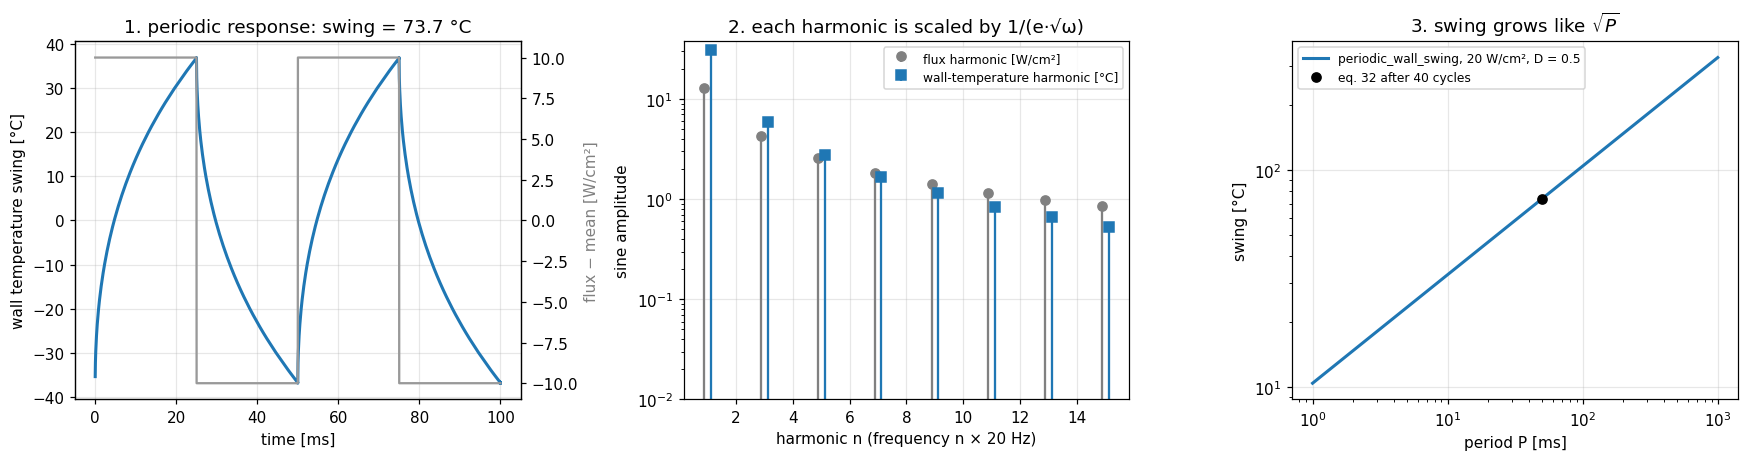

In [52]:
def demo_periodic_wall_swing():
    A, P, D, M = Q_PEAK, P_SQ, 0.5, 4096
    tt = np.arange(M) / M * P; qz = A * ((tt < D * P) - D)
    Q = np.fft.rfft(qz); w = 2 * np.pi * np.fft.rfftfreq(M, P / M)
    Th = np.zeros_like(Q); Th[1:] = Q[1:] / (E_EFF * np.sqrt(1j * w[1:])); th = np.fft.irfft(Th, M)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
    a = ax[0]; t2 = np.concatenate([tt, tt + P]) * 1e3
    a.plot(t2, np.tile(th, 2), 'tab:blue', lw=2); a.set(xlabel='time [ms]', ylabel='wall temperature swing [°C]', title=f'1. periodic response: swing = {th.max()-th.min():.1f} °C')
    b = a.twinx(); b.plot(t2, np.tile(qz, 2) / 1e4, color='0.6'); b.set_ylabel("flux − mean [W/cm²]", color='0.5'); b.grid(False)
    a = ax[1]; h = np.arange(1, 16); amp_q = 2 * np.abs(Q[h]) / M / 1e4; amp_t = 2 * np.abs(Th[h]) / M
    a.stem(h - 0.12, amp_q, linefmt='0.5', markerfmt='o', basefmt=' ', label='flux harmonic [W/cm²]')
    a.stem(h + 0.12, amp_t, linefmt='C0-', markerfmt='C0s', basefmt=' ', label='wall-temperature harmonic [°C]')
    a.set(yscale='log', ylim=(1e-2, None), xlabel=f'harmonic n (frequency n × {1/P:.0f} Hz)', ylabel='sine amplitude', title='2. each harmonic is scaled by 1/(e·√ω)'); a.legend(fontsize=8)
    a = ax[2]; Ps = np.geomspace(1e-3, 1, 40)
    a.loglog(Ps * 1e3, [periodic_wall_swing(A, p_, D) for p_ in Ps], lw=2, label='periodic_wall_swing, 20 W/cm², D = 0.5')
    a.plot(P * 1e3, last.max() - last.min(), 'ko', label='eq. 32 after 40 cycles')
    a.set(xlabel='period P [ms]', ylabel='swing [°C]', title=r'3. swing grows like $\sqrt{P}$'); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'howto_periodic_wall_swing.png', bbox_inches='tight')

demo_periodic_wall_swing()

,n,median_P_ms,median_abs_A_W_cm2,median_swing_K,p95_swing_K,median_penetration_um
band,,,,,,
P < 10 ms,2560,6.78,2.60,2.26,5.55,9.14
10–50 ms,3689,16.25,3.25,5.01,14.40,14.15
P > 50 ms,1647,118.75,5.78,16.28,52.43,38.25


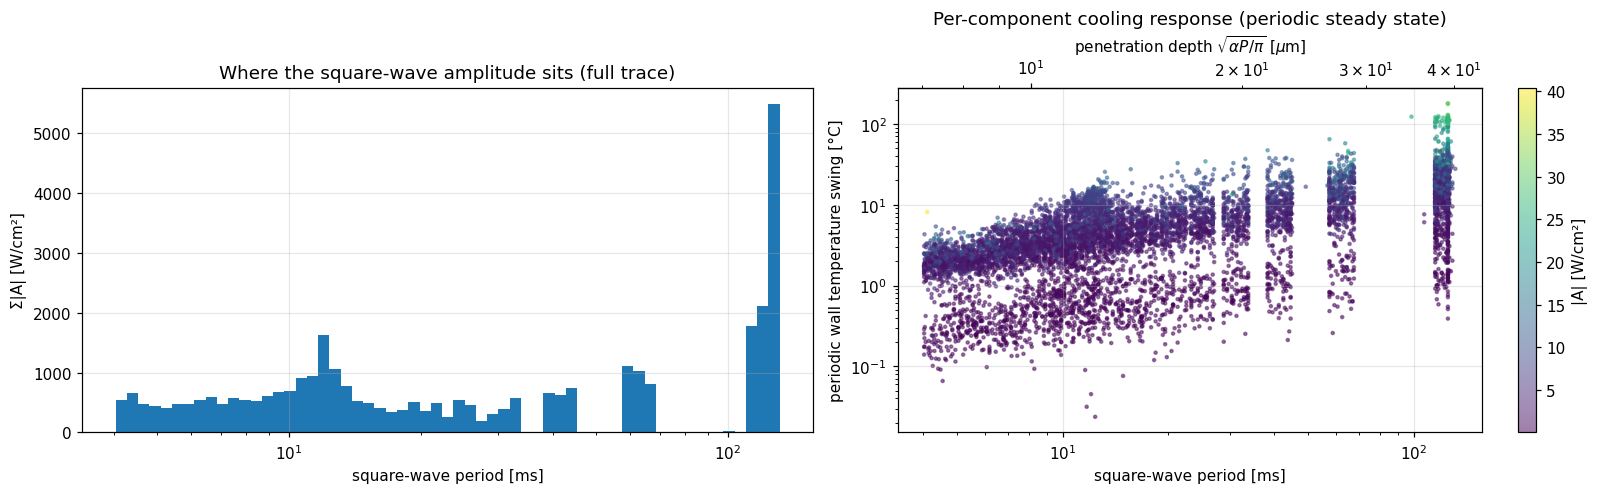

In [53]:
cat = comps_full.drop(columns=['i0', 'i1']).assign(
    P_ms=comps_full.P_s * 1e3, A_W_cm2=comps_full.A / 1e4,
    wall_swing_K=[periodic_wall_swing(r.A, r.P_s, r.duty) for r in comps_full.itertuples()],
    penetration_um=np.sqrt(ALPHA * comps_full.P_s / np.pi) * 1e6,
)
cat['within_model'] = cat.penetration_um < Y_MAX * 1e6
cat['band'] = pd.cut(cat.P_s, [0, 0.01, 0.05, np.inf], labels=['P < 10 ms', '10–50 ms', 'P > 50 ms'], right=False)
cat.to_csv(OUT / 'full_trace_square_wave_catalogue.csv', index=False)
summary = cat.groupby('band', observed=True).agg(n=('P_ms', 'size'), median_P_ms=('P_ms', 'median'),
    median_abs_A_W_cm2=('A_W_cm2', lambda a: np.median(np.abs(a))), median_swing_K=('wall_swing_K', 'median'),
    p95_swing_K=('wall_swing_K', lambda s: np.percentile(s, 95)), median_penetration_um=('penetration_um', 'median'))
display(summary.round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].hist(cat.P_ms, bins=np.geomspace(cat.P_ms.min(), cat.P_ms.max(), 60), weights=np.abs(cat.A_W_cm2), color='tab:blue')
ax[0].set(xscale='log', xlabel='square-wave period [ms]', ylabel='Σ|A| [W/cm²]', title='Where the square-wave amplitude sits (full trace)')
sc = ax[1].scatter(cat.P_ms, cat.wall_swing_K, c=np.abs(cat.A_W_cm2), cmap='viridis', s=4, alpha=0.5)
ax[1].set(xscale='log', yscale='log', xlabel='square-wave period [ms]', ylabel='periodic wall temperature swing [°C]',
          title='Per-component cooling response (periodic steady state)')
ax2 = ax[1].secondary_xaxis('top', functions=(lambda P: np.sqrt(ALPHA * np.asarray(P) / 1e3 / np.pi) * 1e6,
                                               lambda d: np.pi * (np.asarray(d) / 1e6) ** 2 / ALPHA * 1e3))
ax2.set_xlabel(r'penetration depth $\sqrt{\alpha P/\pi}$ [$\mu$m]')
fig.colorbar(sc, ax=ax[1], label='|A| [W/cm²]')
fig.tight_layout(); fig.savefig(FIG / 'part5_full_trace_catalogue.png', bbox_inches='tight');

## Part 6: Key findings, illustrated

The same findings as above, one figure each, in plain terms. Think of the liquid as a **signal-processing system**: GPU power goes in, the temperature of the surface the chip touches (the *wall*) comes out. The system is linear and time-invariant, so the output is the input convolved with a fixed impulse response. Temperatures here are *changes*, so kelvin and °C are the same.

Colours are consistent throughout: grey = power, blue = the main result, orange = the thing it's compared against.

In [54]:
POWER_C, MAIN_C, CMP_C, THIRD_C = '0.45', 'tab:blue', 'tab:orange', 'tab:green'

def detrend_ends(x, n=10):
    '''Remove the straight line joining the average of the first and last n samples (hides the slow sqrt(t) climb).'''
    return x - np.linspace(x[:n].mean(), x[-n:].mean(), len(x))

def theta_wall_drain(q, dt, h, e=E_EFF):
    '''Wall superheat [K] like theta_grid(q, dt, [0])[0], but with a "drain": the wall also loses h * Theta_w [W/m^2]
    (h = heat-transfer coefficient, e.g. from boiling). Step response: (1/h) * (1 - erfcx(h*sqrt(t)/e)), which starts
    like the no-drain sqrt(t) curve and levels off at 1/h instead of growing forever.'''
    from scipy.special import erfcx
    dq = np.diff(np.concatenate([[0.0], q]))
    kern = (1 - erfcx(h * np.sqrt(np.arange(len(q)) * dt) / e)) / h
    return fftconvolve(dq, kern)[:len(q)]

xs = (tg >= ZOOM[0]) & (tg < ZOOM[1])                    # the same 300 ms excerpt as before
t_ms = (tg[xs] - tg[xs][0]) * 1e3

### 0. The liquid is a weak low-pass filter with long memory

* **Left:** the response to a single 1 ms burst of 20 W/cm² (blue), next to a typical RC-style filter with the same peak (orange). Both heat up during the burst. The RC filter forgets it within a few ms; the liquid doesn't.
* **Middle:** the same on log–log axes. The liquid's memory fades only like $1/\sqrt{t}$, a straight line of slope −½. After 100 ms it still holds about 5% of the peak.
* **Right:** the frequency response (Bode-style, normalised at 1 Hz). Fast power changes are damped only like $1/\sqrt{f}$, much more gently than a $1/f$ filter. At 100 Hz the liquid still passes 10%, versus 1% for the $1/f$ filter.

Every other finding follows from these two properties.

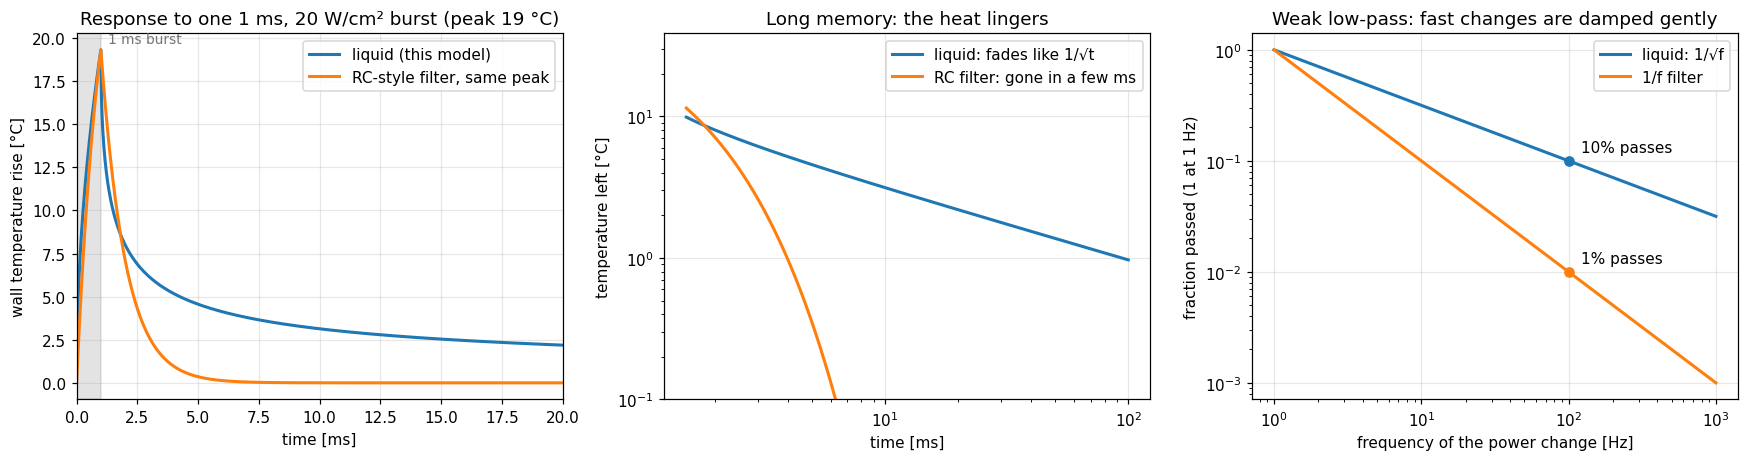

In [55]:
def finding0():
    q, tau = 20e4, 1e-3
    t = np.linspace(0, 0.1, 4001)
    liq = q * (theta_kernel(0, t) - theta_kernel(0, t - tau))
    peak = liq.max(); T = 1e-3
    rc = np.where(t < tau, peak * (1 - np.exp(-t / T)) / (1 - np.exp(-tau / T)), peak * np.exp(-(t - tau) / T))
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
    a = ax[0]
    a.axvspan(0, tau * 1e3, color=POWER_C, alpha=0.2)
    a.text(tau * 1e3 + 0.3, peak * 1.02, '1 ms burst', color=POWER_C, fontsize=9)
    a.plot(t * 1e3, liq, color=MAIN_C, lw=2, label='liquid (this model)')
    a.plot(t * 1e3, rc, color=CMP_C, lw=2, label='RC-style filter, same peak')
    a.set(xlim=(0, 20), xlabel='time [ms]', ylabel='wall temperature rise [°C]', title=f'Response to one 1 ms, 20 W/cm² burst (peak {peak:.0f} °C)'); a.legend()
    a = ax[1]; m = t > tau * 1.5
    a.loglog(t[m] * 1e3, liq[m], color=MAIN_C, lw=2, label='liquid: fades like 1/√t')
    a.loglog(t[m] * 1e3, np.maximum(rc[m], 1e-6), color=CMP_C, lw=2, label='RC filter: gone in a few ms')
    a.set(ylim=(1e-1, 2 * peak), xlabel='time [ms]', ylabel='temperature left [°C]', title='Long memory: the heat lingers'); a.legend()
    a = ax[2]; f = np.geomspace(1, 1000, 200)
    a.loglog(f, 1 / np.sqrt(f), color=MAIN_C, lw=2, label='liquid: 1/√f')
    a.loglog(f, 1 / f, color=CMP_C, lw=2, label='1/f filter')
    for ff in [100]:
        a.plot(ff, 1 / np.sqrt(ff), 'o', color=MAIN_C); a.annotate('10% passes', (ff, 1 / np.sqrt(ff)), xytext=(8, 6), textcoords='offset points')
        a.plot(ff, 1 / ff, 'o', color=CMP_C); a.annotate('1% passes', (ff, 1 / ff), xytext=(8, 6), textcoords='offset points')
    a.set(xlabel='frequency of the power change [Hz]', ylabel='fraction passed (1 at 1 Hz)', title='Weak low-pass: fast changes are damped gently'); a.legend()
    fig.tight_layout(); fig.savefig(FIG / 'finding0_filter.png', bbox_inches='tight')

finding0()

### 1. Power jitter causes real temperature jitter, and a "few clean periodic signals" model misses it

* **Left:** the fast part of the wall temperature (slow climb removed) over the 300 ms excerpt. Blue comes from the real power trace. Orange is what you'd predict if you modelled the power as a few clean periodic waves spanning the whole run. Orange is almost flat.
* **Right:** the size of the jitter over the whole factorization (RMS, a typical deviation). It's about 11 °C from the real trace. The windowed square-wave fit gets the same, and the few-periodic-waves model predicts about 15× too little.

It's like sizing a network link for average traffic and missing the bursts.

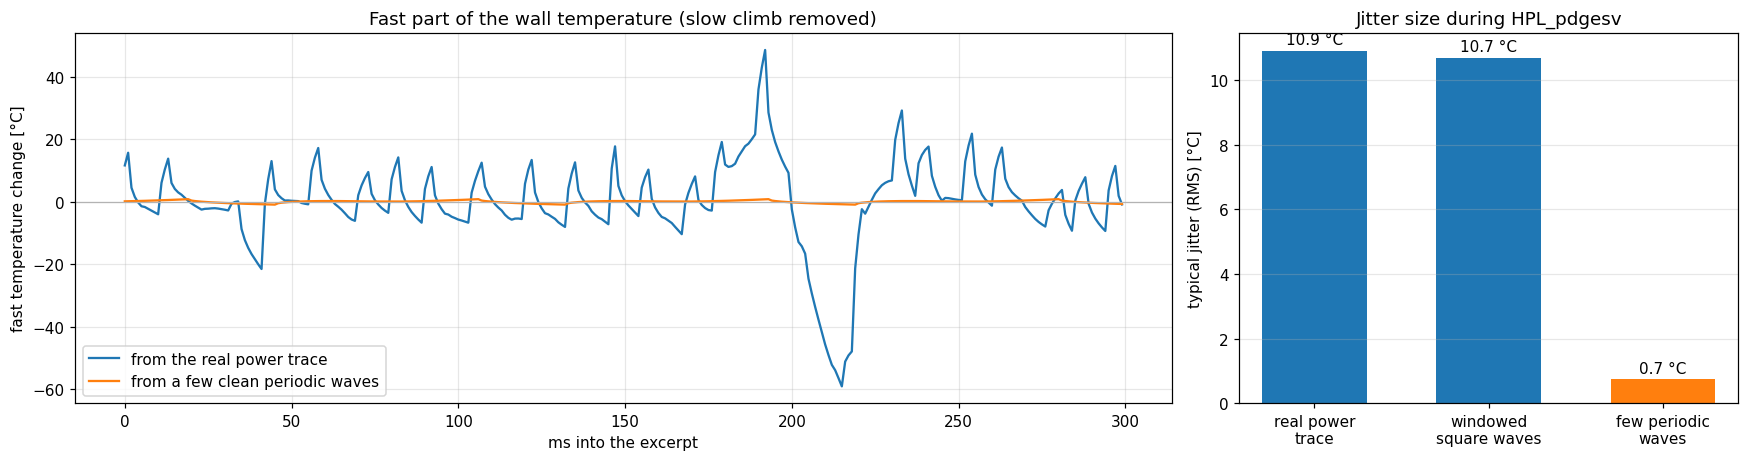

In [56]:
def finding1():
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.3), gridspec_kw={'width_ratios': [2.2, 1]})
    a = ax[0]
    a.plot(t_ms, hp(wall_trace)[xs], color=MAIN_C, lw=1.5, label='from the real power trace')
    a.plot(t_ms, hp(wall_glob)[xs], color=CMP_C, lw=1.5, label='from a few clean periodic waves')
    a.axhline(0, color='0.7', lw=0.8)
    a.set(xlabel='ms into the excerpt', ylabel='fast temperature change [°C]', title='Fast part of the wall temperature (slow climb removed)'); a.legend(loc='lower left')
    a = ax[1]
    vals = [np.std(hp(wall_trace)[in_g]), np.std(hp(wall_sw)[in_g]), np.std(hp(wall_glob)[in_g])]
    labs = ['real power\ntrace', 'windowed\nsquare waves', 'few periodic\nwaves']
    bars = a.bar(labs, vals, color=[MAIN_C, MAIN_C, CMP_C], width=0.6)
    for b_, v in zip(bars, vals):
        a.text(b_.get_x() + b_.get_width() / 2, v + 0.2, f'{v:.1f} °C', ha='center')
    a.set(ylabel='typical jitter (RMS) [°C]', title='Jitter size during HPL_pdgesv'); a.grid(axis='x', visible=False)
    fig.tight_layout(); fig.savefig(FIG / 'finding1_jitter.png', bbox_inches='tight')

finding1()

### 2. The two biggest events: panel-step stalls and DGEMM bursts

Top: GPU power over the 300 ms excerpt. Bottom: the wall temperature change it causes (slow climb removed).

* When the GPU stalls (the panel-step dip, power falls to about 10 W/cm²), the wall **cools by about 100+ °C within about 25 ms**.
* Each DGEMM burst heats the wall by **tens of °C within a few ms**. The largest burst rise in this excerpt is annotated.

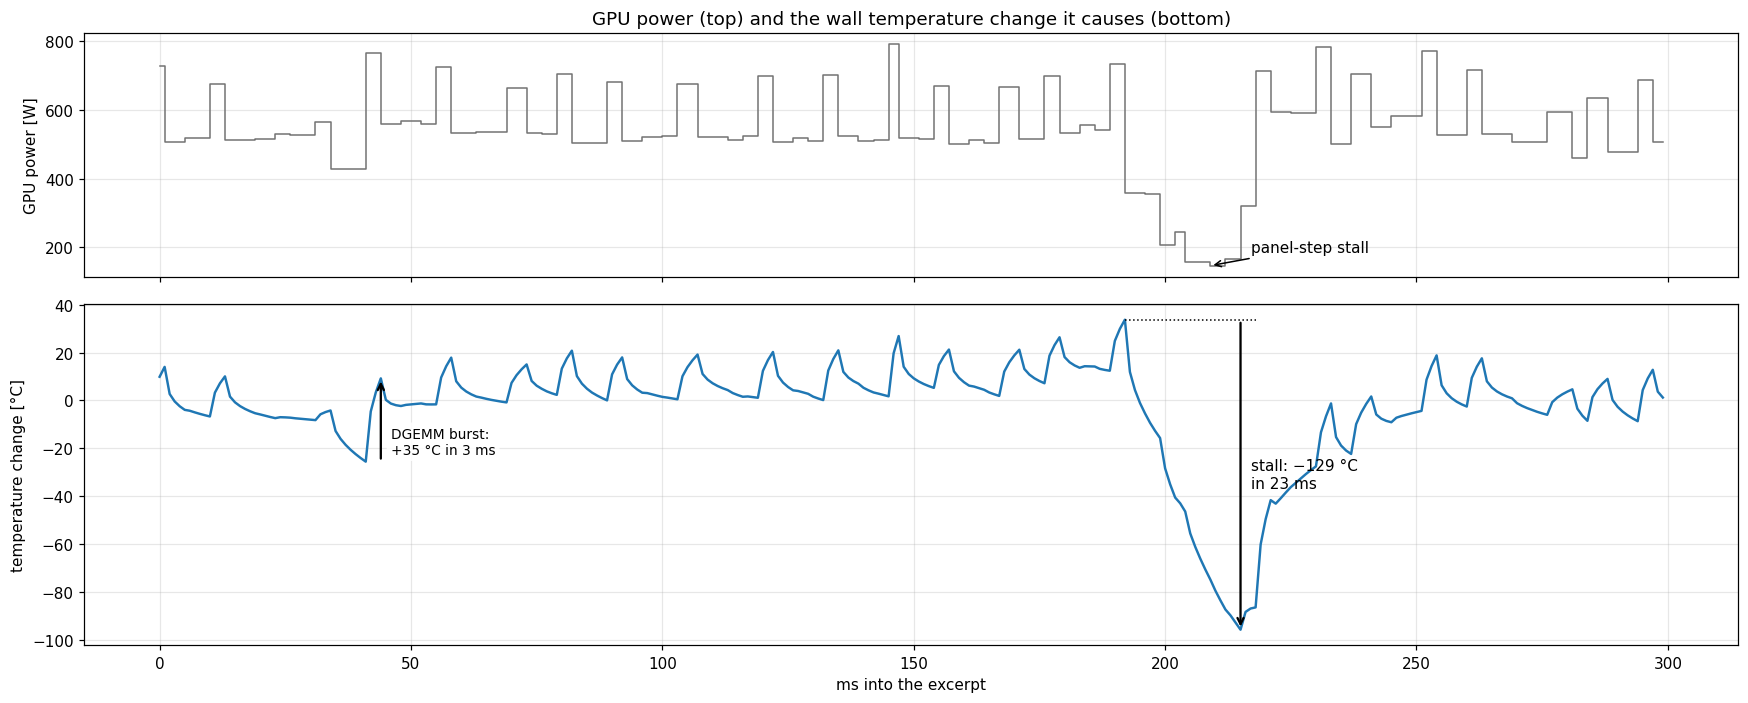

In [57]:
def finding2():
    qx, wx = pg[xs], detrend_ends(wall_trace[xs])
    fig, ax = plt.subplots(2, 1, figsize=(16, 6.5), sharex=True, gridspec_kw={'height_ratios': [1, 1.4]})
    ax[0].step(t_ms, qx, where='post', color=POWER_C, lw=1)
    ax[0].set(ylabel='GPU power [W]', title='GPU power (top) and the wall temperature change it causes (bottom)')
    ax[1].plot(t_ms, wx, color=MAIN_C, lw=1.6)
    ax[1].set(xlabel='ms into the excerpt', ylabel='temperature change [°C]')
    i_dip = np.argmin(qx)
    pre = slice(max(i_dip - 40, 0), i_dip); post = slice(i_dip, min(i_dip + 30, len(wx)))
    i_hi = pre.start + np.argmax(wx[pre]); i_lo = post.start + np.argmin(wx[post])
    ax[1].plot([t_ms[i_hi], t_ms[i_lo] + 3], [wx[i_hi]] * 2, ':', color='k', lw=1)
    ax[1].annotate('', xy=(t_ms[i_lo], wx[i_lo]), xytext=(t_ms[i_lo], wx[i_hi]), arrowprops=dict(arrowstyle='->', lw=1.5))
    ax[1].text(t_ms[i_lo] + 2, (wx[i_hi] + wx[i_lo]) / 2, f'stall: −{wx[i_hi]-wx[i_lo]:.0f} °C\nin {t_ms[i_lo]-t_ms[i_hi]:.0f} ms', va='center')
    ax[0].annotate('panel-step stall', (t_ms[i_dip], qx[i_dip]), xytext=(t_ms[i_dip] + 8, qx[i_dip] + 40), arrowprops=dict(arrowstyle='->'))
    L = 8; rise = wx[L:] - wx[:-L]
    far = np.abs(np.arange(len(rise)) - i_dip) > 45
    i_b = np.flatnonzero(far)[np.argmax(rise[far])]; i_b2 = i_b + L
    i_b = i_b + np.argmin(wx[i_b:i_b2]); i_b2 = i_b + np.argmax(wx[i_b:i_b + L])
    ax[1].annotate('', xy=(t_ms[i_b2], wx[i_b2]), xytext=(t_ms[i_b2], wx[i_b]), arrowprops=dict(arrowstyle='->', lw=1.5))
    ax[1].text(t_ms[i_b2] + 2, wx[i_b] + 2, f'DGEMM burst:\n+{wx[i_b2]-wx[i_b]:.0f} °C in {t_ms[i_b2]-t_ms[i_b]:.0f} ms', va='bottom', fontsize=9,
               bbox=dict(boxstyle='round', fc='white', ec='none', alpha=0.85))
    fig.tight_layout(); fig.savefig(FIG / 'finding2_events.png', bbox_inches='tight')

finding2()

### 3. Short bursts aren't negligible

* **Left:** how much one burst of 20 W/cm² (about 290 W of GPU power) heats the wall, as a function of how long it lasts. Both axes are logarithmic, so the straight line means the rise grows like $\sqrt{\text{duration}}$: a burst 100× shorter is only 10× cooler. A 1 ms burst still gives about 19 °C.
* **Right:** the typical (median) and large (95th percentile) temperature swing caused by each fitted square wave, grouped by how fast it is. Faster fluctuations matter less, but not much less.

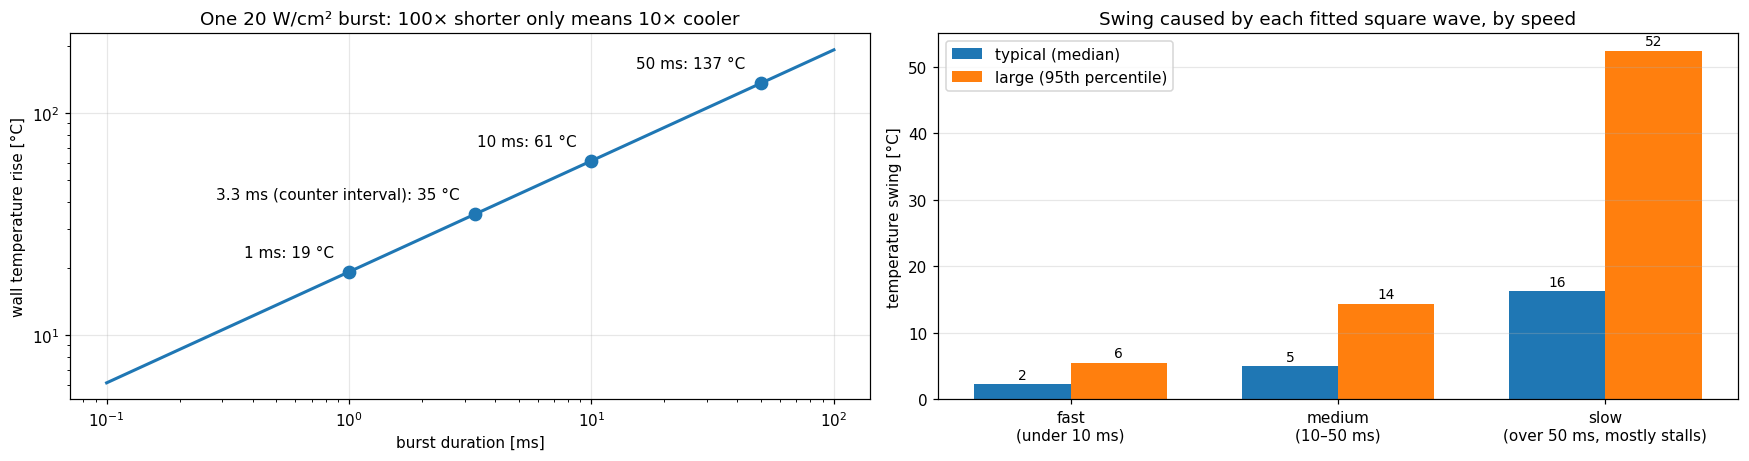

In [58]:
def finding3():
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.3))
    a = ax[0]; q = 20e4; tau = np.geomspace(1e-4, 0.1, 200)
    rise = 2 * q * np.sqrt(tau) / (E_EFF * np.sqrt(np.pi))
    a.plot(tau * 1e3, rise, color=MAIN_C, lw=2)
    for tt, lab in [(1e-3, '1 ms'), (3.3e-3, '3.3 ms (counter interval)'), (10e-3, '10 ms'), (50e-3, '50 ms')]:
        r_ = 2 * q * np.sqrt(tt) / (E_EFF * np.sqrt(np.pi)); a.plot(tt * 1e3, r_, 'o', color=MAIN_C, ms=8)
        a.annotate(f'{lab}: {r_:.0f} °C', (tt * 1e3, r_), xytext=(-10, 10), textcoords='offset points', ha='right')
    a.set(xscale='log', yscale='log', xlabel='burst duration [ms]', ylabel='wall temperature rise [°C]',
          title='One 20 W/cm² burst: 100× shorter only means 10× cooler')
    a = ax[1]
    order = ['P < 10 ms', '10–50 ms', 'P > 50 ms']
    g = cat.groupby('band', observed=True).wall_swing_K
    med = g.median().reindex(order); p95 = g.quantile(0.95).reindex(order)
    x = np.arange(len(order)); wdt = 0.36
    b1 = a.bar(x - wdt / 2, med, wdt, color=MAIN_C, label='typical (median)')
    b2 = a.bar(x + wdt / 2, p95, wdt, color=CMP_C, label='large (95th percentile)')
    for bb in list(b1) + list(b2):
        a.text(bb.get_x() + bb.get_width() / 2, bb.get_height() + 0.8, f'{bb.get_height():.0f}', ha='center', fontsize=9)
    a.set_xticks(x); a.set_xticklabels(['fast\n(under 10 ms)', 'medium\n(10–50 ms)', 'slow\n(over 50 ms, mostly stalls)'])
    a.set(ylabel='temperature swing [°C]', title='Swing caused by each fitted square wave, by speed'); a.legend(); a.grid(axis='x', visible=False)
    fig.tight_layout(); fig.savefig(FIG / 'finding3_short_bursts.png', bbox_inches='tight')

finding3()

### 4. The profiler's sample rate hides the sharpest spikes

**Made-up illustration, not measured data.** Short 1 ms power spikes (grey, top) as the energy counter would report them: averaged over its ~3.3 ms intervals (orange, top). The counter keeps the energy but flattens the peaks. Bottom: the wall temperature the model predicts from each. The "as measured" version under-reports the temperature peaks, so the jitter we computed from the real trace is a **lower bound**.

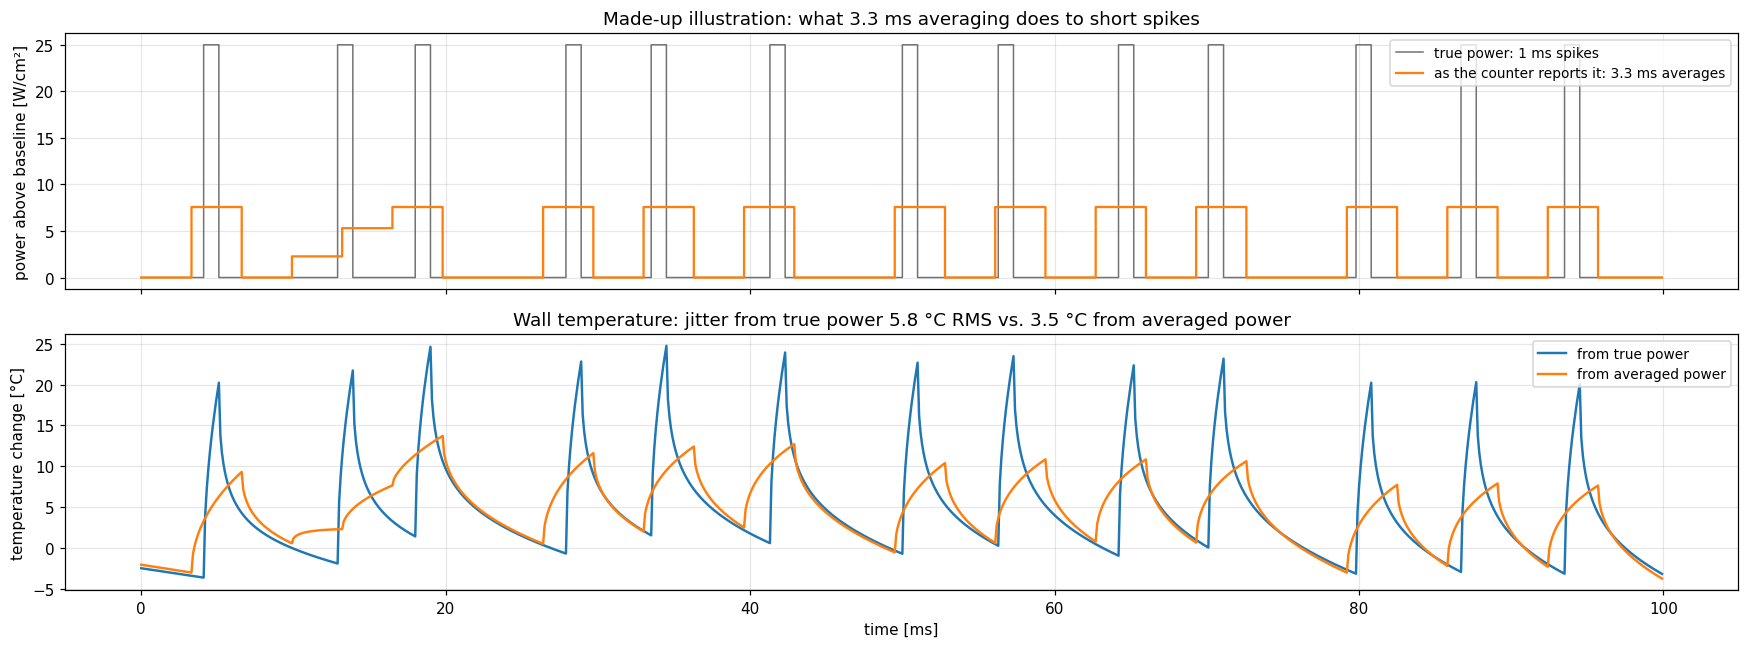

In [59]:
def finding4():
    dt = 1e-4; t = np.arange(0, 0.1, dt); rng = np.random.default_rng(1)
    q = np.zeros_like(t)
    for st in np.arange(0.004, 0.095, 0.0075) + rng.uniform(-0.0015, 0.0015, 13):
        q[(t >= st) & (t < st + 0.001)] = 25e4
    edges = np.arange(0, t[-1] + 0.0033, 0.0033)
    qa = q.copy()
    for a_, b_ in zip(edges[:-1], edges[1:]):
        m = (t >= a_) & (t < b_); qa[m] = q[m].mean()
    th, tha = theta_grid(q, dt, [0.0])[0], theta_grid(qa, dt, [0.0])[0]
    fig, ax = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
    ax[0].step(t * 1e3, q / 1e4, where='post', color=POWER_C, lw=1, label='true power: 1 ms spikes')
    ax[0].step(t * 1e3, qa / 1e4, where='post', color=CMP_C, lw=1.5, label='as the counter reports it: 3.3 ms averages')
    ax[0].set(ylabel='power above baseline [W/cm²]', title='Made-up illustration: what 3.3 ms averaging does to short spikes'); ax[0].legend(loc='upper right', fontsize=9)
    ax[1].plot(t * 1e3, detrend_ends(th, 50), color=MAIN_C, lw=1.6, label='from true power')
    ax[1].plot(t * 1e3, detrend_ends(tha, 50), color=CMP_C, lw=1.6, label='from averaged power')
    ax[1].set(xlabel='time [ms]', ylabel='temperature change [°C]',
              title=f'Wall temperature: jitter from true power {np.std(hp_fine(th)):.1f} °C RMS vs. {np.std(hp_fine(tha)):.1f} °C from averaged power'); ax[1].legend(fontsize=9)
    fig.tight_layout(); fig.savefig(FIG / 'finding4_sampling.png', bbox_inches='tight')

hp_fine = lambda x: x - uniform_filter1d(x, 200)          # 20 ms moving average removed, on the 0.1 ms grid
finding4()

### 5. Order and spacing of work matter, not just total energy

Five identical bursts (same total energy, in joules) run two ways: **back-to-back** (orange) and **spread out** (blue). Because the liquid drains heat slowly, back-to-back bursts stack before the heat leaves, and the peak temperature is much higher. In scheduling terms: kernel ordering and spacing change the peak surface temperature even when average power is identical.

### 6. Fast jitter only reaches a thin skin of liquid

How big the temperature jitter is at each distance from the wall, during the factorization, split by how fast the power fluctuation is. The faster the fluctuation, the thinner the layer it reaches: half of the fast jitter is gone within about 10 µm, and almost all jitter within a human hair's width (about 70 µm). Bubbles form right at the surface, so this thin skin is exactly what decides when boiling starts. The right panel shows the same as a fraction of the value at the wall.

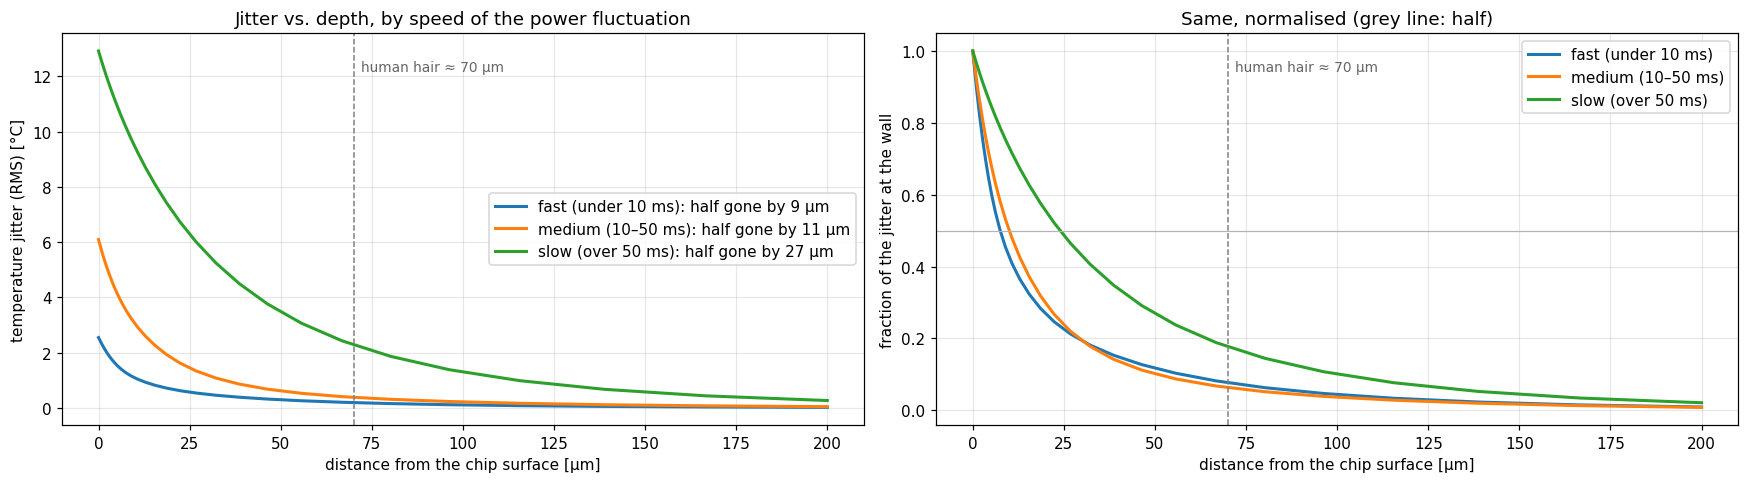

In [60]:
def finding6():
    ys = np.concatenate([[0.0], np.geomspace(1e-6, 200e-6, 30)])
    order = [('P < 10 ms', 'fast (under 10 ms)', MAIN_C), ('10–50 ms', 'medium (10–50 ms)', CMP_C), ('P > 50 ms', 'slow (over 50 ms)', THIRD_C)]
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
    for key, lab, col in order:
        fld = theta_grid(band_flux[key], GRID_DT, ys)
        fld = fld - uniform_filter1d(fld, int(0.5 / GRID_DT), axis=-1)       # remove the slow drift
        rms = fld[:, in_g].std(axis=1)
        d50 = ys[np.argmax(rms < 0.5 * rms[0])] * 1e6
        ax[0].plot(ys * 1e6, rms, color=col, lw=2, label=f'{lab}: half gone by {d50:.0f} µm')
        ax[1].plot(ys * 1e6, rms / rms[0], color=col, lw=2, label=lab)
    for a in ax:
        a.axvline(70, color='0.5', ls='--', lw=1); a.text(72, a.get_ylim()[1] * 0.9, 'human hair ≈ 70 µm', color='0.4', fontsize=9)
        a.set(xlabel='distance from the chip surface [µm]')
    ax[0].set(ylabel='temperature jitter (RMS) [°C]', title='Jitter vs. depth, by speed of the power fluctuation'); ax[0].legend()
    ax[1].axhline(0.5, color='0.7', lw=0.8)
    ax[1].set(ylabel='fraction of the jitter at the wall', title='Same, normalised (grey line: half)'); ax[1].legend()
    fig.tight_layout(); fig.savefig(FIG / 'finding6_depth.png', bbox_inches='tight')

finding6()

### 7. The big caveat: the model has no drain

The model only lets heat *in*, so it's a bucket with no drain. Temperature climbs forever, which gives the meaningless 8 500 °C by the end of the run. In reality, once the surface is some tens of °C above boiling, bubbles form and carry heat away.

As a **rough sketch** of what fixing that does, a drain is added here: the wall loses $h\,\Theta_w$ with $h$ = 1.2×10⁴ W/m²K, a back-of-envelope value for nucleate boiling ($h \approx q/\Delta T \approx$ 30 W/cm² ÷ 25 °C). This is *not* a validated boiling model.

* **Left:** with the drain, the temperature levels off around $\bar q/h$ (tens of °C) instead of growing without bound. Note the log scale.
* **Middle:** the fast jitter over the 300 ms excerpt, with and without the drain. The drain shrinks it, and shrinks the slow stall dip most.
* **Right:** the fraction of each fluctuation that survives the drain, by fluctuation period, for three drain strengths. Fast fluctuations survive best because the drain has less time to act on them.

with drain: mean wall temperature above boiling during HPL_pdgesv 31 °C; fast jitter 3.9 °C RMS vs 10.9 °C without


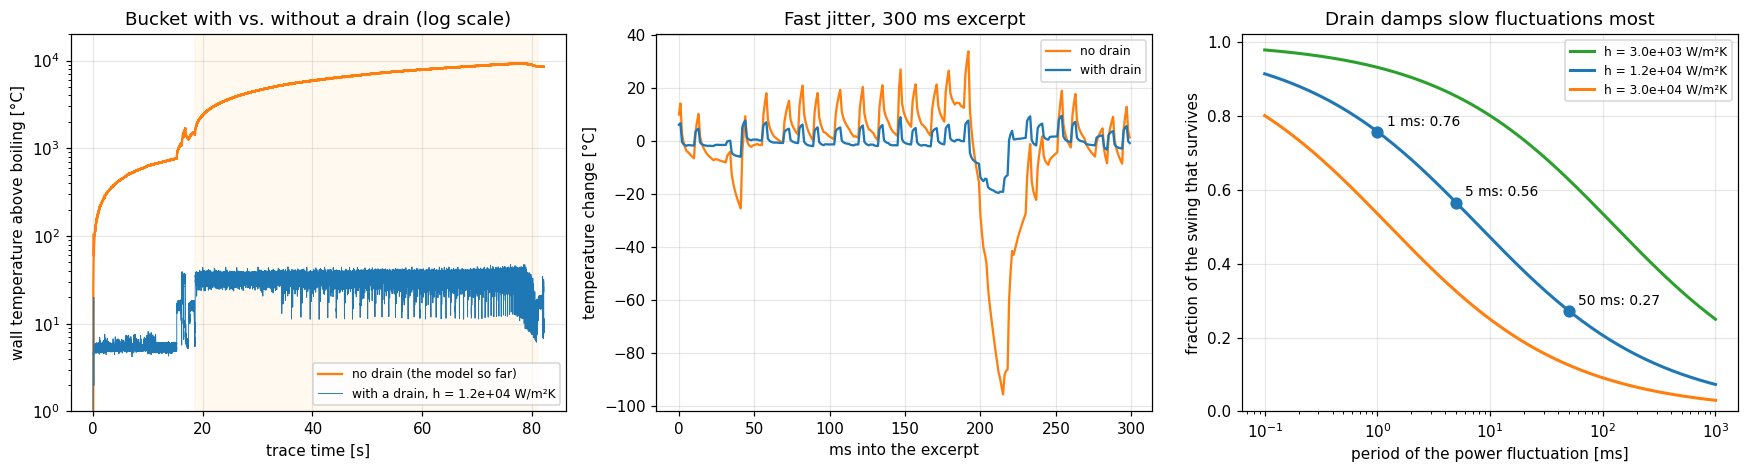

In [61]:
H_BOIL = 1.2e4
wall_drain = theta_wall_drain(q_full, GRID_DT, H_BOIL)

def finding7():
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    a = ax[0]
    a.plot(tg, wall_trace, color=CMP_C, lw=1.5, label='no drain (the model so far)')
    a.plot(tg, wall_drain, color=MAIN_C, lw=0.6, label=f'with a drain, h = {H_BOIL:.1e} W/m²K')
    a.axvspan(G0, G1, color='orange', alpha=0.06)
    a.set(yscale='log', ylim=(1, 2e4), xlabel='trace time [s]', ylabel='wall temperature above boiling [°C]', title='Bucket with vs. without a drain (log scale)'); a.legend(loc='lower right', fontsize=8)
    a = ax[1]
    a.plot(t_ms, detrend_ends(wall_trace[xs]), color=CMP_C, lw=1.5, label='no drain')
    a.plot(t_ms, detrend_ends(wall_drain[xs]), color=MAIN_C, lw=1.5, label='with drain')
    a.set(xlabel='ms into the excerpt', ylabel='temperature change [°C]', title='Fast jitter, 300 ms excerpt'); a.legend(fontsize=8)
    a = ax[2]; P = np.geomspace(1e-4, 1, 200); w = 2 * np.pi / P
    for h, col in [(3e3, THIRD_C), (1.2e4, MAIN_C), (3e4, CMP_C)]:
        kept = np.abs(E_EFF * np.sqrt(1j * w)) / np.abs(h + E_EFF * np.sqrt(1j * w))
        a.plot(P * 1e3, kept, color=col, lw=2, label=f'h = {h:.1e} W/m²K')
    for Pm in [1e-3, 5e-3, 50e-3]:
        wm = 2 * np.pi / Pm; km = np.abs(E_EFF * np.sqrt(1j * wm)) / np.abs(H_BOIL + E_EFF * np.sqrt(1j * wm))
        a.plot(Pm * 1e3, km, 'o', color=MAIN_C, ms=7); a.annotate(f'{Pm*1e3:.0f} ms: {km:.2f}', (Pm * 1e3, km), xytext=(6, 4), textcoords='offset points', fontsize=9)
    a.set(xscale='log', ylim=(0, 1.02), xlabel='period of the power fluctuation [ms]', ylabel='fraction of the swing that survives',
          title='Drain damps slow fluctuations most'); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'finding7_drain.png', bbox_inches='tight')
    print(f"with drain: mean wall temperature above boiling during HPL_pdgesv {wall_drain[in_g].mean():.0f} °C; "
          f"fast jitter {np.std(hp(wall_drain)[in_g]):.1f} °C RMS vs {np.std(hp(wall_trace)[in_g]):.1f} °C without")

finding7()

### Next steps (no figures yet)

1. **Add the drain properly**, using a real boiling-curve model rather than a fixed $h$. That turns the temperatures above into realistic ones.
2. **Count threshold crossings, not jitter size**: how often the surface crosses the boiling-onset temperature, like counting SLA violations instead of reporting a standard deviation.
3. **Attribute thermal events to code**: line up the ~12 ms rhythm and the stalls with the Ampere call graph (DGEMM, panel factorization, broadcast). Profiling, but for temperature.
4. **Use a trace with a faster energy counter** (after the February driver change, if one exists) to see what the 3.3 ms averaging hides.

## Appendix: Recovering the fluid properties from `liquid_BL_results.pdf`

* **Effusivity:** the blue wall curve was extracted from the PDF's vector paths (`reference/liquid_BL_results_wall_superheat.csv`). Because $\Theta_w = \frac{2}{e\sqrt\pi}\,q''_{peak}\,S(t)$ with a known shape $S(t)$, $1/e$ is a 1-parameter linear least-squares fit.
* **Diffusivity:** the heatmap is an embedded raster (`reference/liquid_BL_results_heatmap.jpg`). Pixels are decoded to K using the colorbar image, and $\alpha$ is fitted to $\Theta(y,t)$ on the 0–500 µm × 0–250 ms grid.

In [62]:
from scipy.optimize import minimize_scalar
from PIL import Image

# Effusivity from the wall curve
S_shape = theta_square_wave(0, ref.t_ms.values / 1e3, Q_PEAK, P_SQ, T_ON, e=1.0)     # = e * theta
e_fit = (S_shape @ S_shape) / (S_shape @ ref.theta_w_K.values)
print(f"effusivity fit: {e_fit:.2f}")

# Diffusivity from the heatmap raster
H = np.asarray(Image.open(ROOT / 'reference' / 'liquid_BL_results_heatmap.jpg').convert('RGB')).astype(float)
C = np.asarray(Image.open(ROOT / 'reference' / 'liquid_BL_results_colorbar.jpg').convert('RGB')).astype(float)
cbar = C[:, 5:16].mean(1); cvals = np.linspace(ref.theta_w_K.max(), 0, len(cbar))     # colorbar spans 0..max(theta)
img_K = cvals[((H.reshape(-1, 3)[:, None] - cbar[None]) ** 2).sum(-1).argmin(1)].reshape(H.shape[:2])
nr, nc = img_K.shape
yy = (nr - 0.5 - np.arange(nr)) / nr * Y_MAX; tt_ = (np.arange(nc) + 0.5) / nc * T_END
Yi, Ti = np.meshgrid(yy, tt_, indexing='ij')
mask = np.ones_like(img_K, bool); mask[85:100] = False                                 # skip the white marker line
cost = lambda la: np.sqrt(np.mean((theta_square_wave(Yi, Ti, Q_PEAK, P_SQ, T_ON, alpha=10**la, e=e_fit) - img_K)[mask] ** 2))
res = minimize_scalar(cost, bounds=(-7.6, -7.2), method='bounded')
print(f"alpha fit: {10**res.x:.4e} m^2/s (pixel RMS {res.fun:.2f} K)  ->  k = {e_fit*np.sqrt(10**res.x):.4f} W/m/K")

effusivity fit: 369.46
alpha fit: 3.8708e-08 m^2/s (pixel RMS 0.39 K)  ->  k = 0.0727 W/m/K
